# Time Series Analysis Project: COVID-19 Global Cases

## 0. Introduction

This project aims to analyse the temporal evolution of the COVID-19 pandemic using publicly available data from the Johns Hopkins University CSSE repository. We focus on **global daily new confirmed cases** as our primary time series. The objectives are:

1. Understand the underlying patterns (trend, seasonality, noise)

2. Build and compare simple forecasting models to predict future cases

3. Critically evaluate the models’ performance and limitations

**Authors**:

Thomas TRAHANT (thomas.trahant@epita.fr)

Eliott MERCIER DEL FORNO (eliott.mercier-del-forno@epita.fr)

Data source: [CSSE Covid data GitHub page](https://github.com/CSSEGISandData/COVID-19/tree/master)

## 1. Data Fetching and Cleaning
The CSSE GitHub repository contains several folders. The most relevant for time series analysis are:

- ```csse_covid_19_time_series``` Contains daily time series data in wide format (```time_series_covid19_confirmed_global.csv```, ```deaths_global.csv```, ```recovered_global.csv```). These are ideal because they already provide a daily timeline for each country.

- ```csse_covid_19_daily_reports``` Daily snapshot reports: less convenient for time series as they require merging.

We will use the confirmed global time series. We aggregate all countries to obtain a single global daily series (or we could have selected a specific country for more interpretable patterns). We choose global totals to capture overall pandemic dynamics, but note that this may smooth out country‑specific effects.

In [52]:
%pip install statsmodels

/home/eliott/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
import itertools
import warnings

from scipy.stats import probplot

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.decomposition import PCA

In [54]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

In [2]:
url_confirmed = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"

df_raw = pd.read_csv(url_confirmed)
print(f"Shape: {df_raw.shape}")
df_raw.head(10)

Shape: (289, 1147)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288
5,NaN,Antarctica,-71.94990,23.347000,0,0,0,0,0,0,...,11,11,11,11,11,11,11,11,11,11
6,NaN,Antigua and Barbuda,17.06080,-61.796400,0,0,0,0,0,0,...,9106,9106,9106,9106,9106,9106,9106,9106,9106,9106
7,NaN,Argentina,-38.41610,-63.616700,0,0,0,0,0,0,...,10044125,10044125,10044125,10044125,10044125,10044125,10044957,10044957,10044957,10044957
8,NaN,Armenia,40.06910,45.038200,0,0,0,0,0,0,...,446819,446819,446819,446819,446819,446819,446819,446819,447308,447308
9,Australian Capital Territory,Australia,-35.47350,149.012400,0,0,0,0,0,0,...,232018,232018,232619,232619,232619,232619,232619,232619,232619,232974


The dataset has columns: ```Province/State```, ```Country/Region```, ```Lat```, ```Long```, and then daily dates from **January, 22nd 2020** to **March, 9th 2023**. We need to reshape it.

In [6]:
# Melt df: convert wide format to long
df_melt = df_raw.melt(id_vars=['Province/State', 'Country/Region', 'Lat', 'Long'],
                      var_name='Date', value_name='Cumulative_Confirmed')

# Date -> datetime
df_melt['Date'] = pd.to_datetime(df_melt['Date'], format='%m/%d/%y')

global_daily = df_melt.groupby('Date')['Cumulative_Confirmed'].sum().reset_index()

global_daily = global_daily.sort_values('Date').reset_index(drop=True)

global_daily['New_Cases'] = global_daily['Cumulative_Confirmed'].diff().fillna(0)

print(global_daily.head())
print(global_daily.tail())
print(global_daily['New_Cases'])
# pk fibrilations
# plot new + recovered + deaths
# plot fpca for all components
# first peak?
# QQ plot after SARIMA

        Date  Cumulative_Confirmed  New_Cases
0 2020-01-22                   557        0.0
1 2020-01-23                   657      100.0
2 2020-01-24                   944      287.0
3 2020-01-25                  1437      493.0
4 2020-01-26                  2120      683.0
           Date  Cumulative_Confirmed  New_Cases
1138 2023-03-05             676024901    56126.0
1139 2023-03-06             676082941    58040.0
1140 2023-03-07             676213378   130437.0
1141 2023-03-08             676392824   179446.0
1142 2023-03-09             676570149   177325.0
0            0.0
1          100.0
2          287.0
3          493.0
4          683.0
          ...   
1138     56126.0
1139     58040.0
1140    130437.0
1141    179446.0
1142    177325.0
Name: New_Cases, Length: 1143, dtype: float64


Recovered and death data are unusable here. The series are incomplete and inconsistent, and plotting them makes the problem obvious.

**Comments on preprocessing**:

We aggregate globally because the repository’s time series already provides country-level data: summing gives a single univariate series.

Daily new cases are computed from cumulative confirmed cases. This removes the upward trend and makes the series more tractable for modelling.

Potential pitfall: Different countries update at different times. Global aggregation may introduce reporting delays. We accept this as inherent to the data.

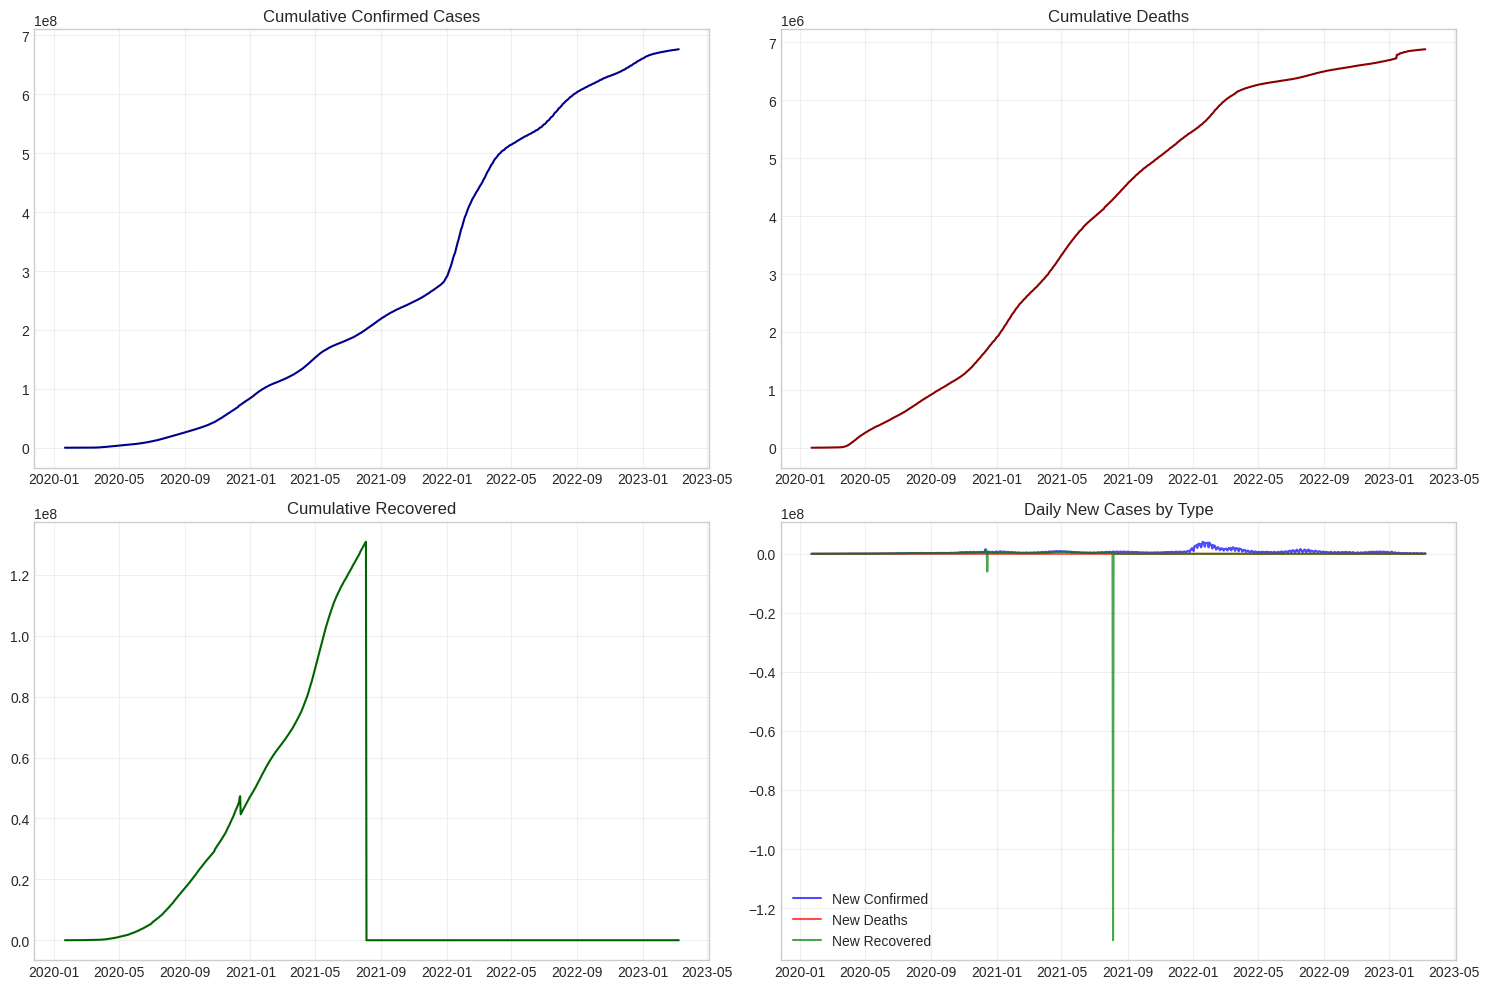

Recovered series completeness: 100.0%
Last non-zero recovered: 2021-08-04 00:00:00


In [57]:
url_deaths = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv"
url_recovered = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_recovered_global.csv"

df_deaths_raw = pd.read_csv(url_deaths)
df_recovered_raw = pd.read_csv(url_recovered)

df_deaths_melt = df_deaths_raw.melt(id_vars=['Province/State', 'Country/Region', 'Lat', 'Long'],
                                        var_name='Date', value_name='Cumulative_Deaths')
df_deaths_melt['Date'] = pd.to_datetime(df_deaths_melt['Date'], format='%m/%d/%y')
global_deaths = df_deaths_melt.groupby('Date')['Cumulative_Deaths'].sum().reset_index()
global_deaths['New_Deaths'] = global_deaths['Cumulative_Deaths'].diff().fillna(0)

df_recovered_melt = df_recovered_raw.melt(id_vars=['Province/State', 'Country/Region', 'Lat', 'Long'],
                                            var_name='Date', value_name='Cumulative_Recovered')
df_recovered_melt['Date'] = pd.to_datetime(df_recovered_melt['Date'], format='%m/%d/%y')
global_recovered = df_recovered_melt.groupby('Date')['Cumulative_Recovered'].sum().reset_index()
global_recovered['New_Recovered'] = global_recovered['Cumulative_Recovered'].diff().fillna(0)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(global_daily['Date'], global_daily['Cumulative_Confirmed'], color='darkblue', label='Confirmed')
axes[0, 0].set_title('Cumulative Confirmed Cases')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(global_deaths['Date'], global_deaths['Cumulative_Deaths'], color='darkred', label='Deaths')
axes[0, 1].set_title('Cumulative Deaths')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(global_recovered['Date'], global_recovered['Cumulative_Recovered'], color='darkgreen', label='Recovered')
axes[1, 0].set_title('Cumulative Recovered')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(global_daily['Date'], global_daily['New_Cases'], color='blue', label='New Confirmed', alpha=0.7)
axes[1, 1].plot(global_deaths['Date'], global_deaths['New_Deaths'], color='red', label='New Deaths', alpha=0.7)
axes[1, 1].plot(global_recovered['Date'], global_recovered['New_Recovered'], color='green', label='New Recovered', alpha=0.7)
axes[1, 1].set_title('Daily New Cases by Type')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Recovered series completeness: {global_recovered['Cumulative_Recovered'].notna().sum() / len(global_recovered) * 100:.1f}%")
print(f"Last non-zero recovered: {global_recovered[global_recovered['Cumulative_Recovered'] > 0]['Date'].max()}")

### 1.1. Why Recovered and Death Data Are Not Used

We attempt to visualize the recovered and death time series to demonstrate why they are unsuitable for this analysis.

## 2. Exploratory Data Analysis - Global Overview

### 2.1. Visualise Cumulative and Daily New Cases

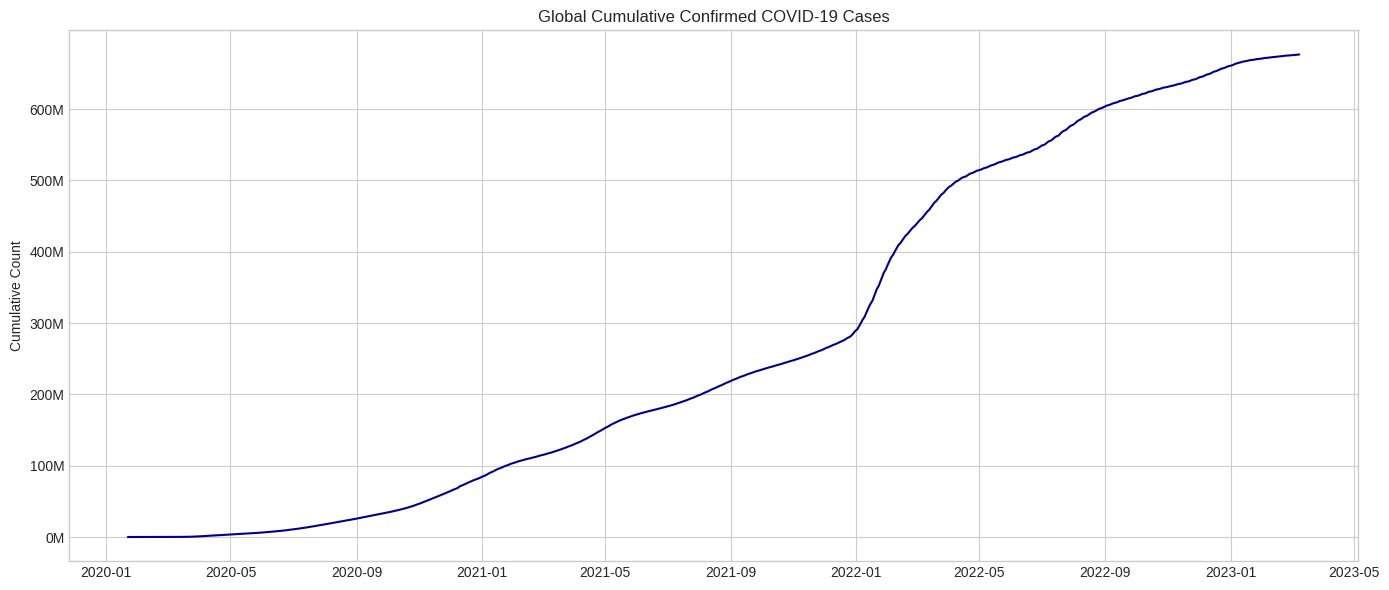

np.int64(676570149)

In [58]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(global_daily['Date'], global_daily['Cumulative_Confirmed'], color='darkblue')
ax.set_title('Global Cumulative Confirmed COVID-19 Cases')
ax.set_ylabel('Cumulative Count')
ax.set_yticks(np.arange(0, global_daily['Cumulative_Confirmed'].max(), 100_000_000))
ax.set_yticklabels([f"{int(y/1_000_000)}M" for y in np.arange(0, global_daily['Cumulative_Confirmed'].max(), 100_000_000)])
ax.grid(True)
plt.tight_layout()
plt.show()
global_daily['Cumulative_Confirmed'].max()

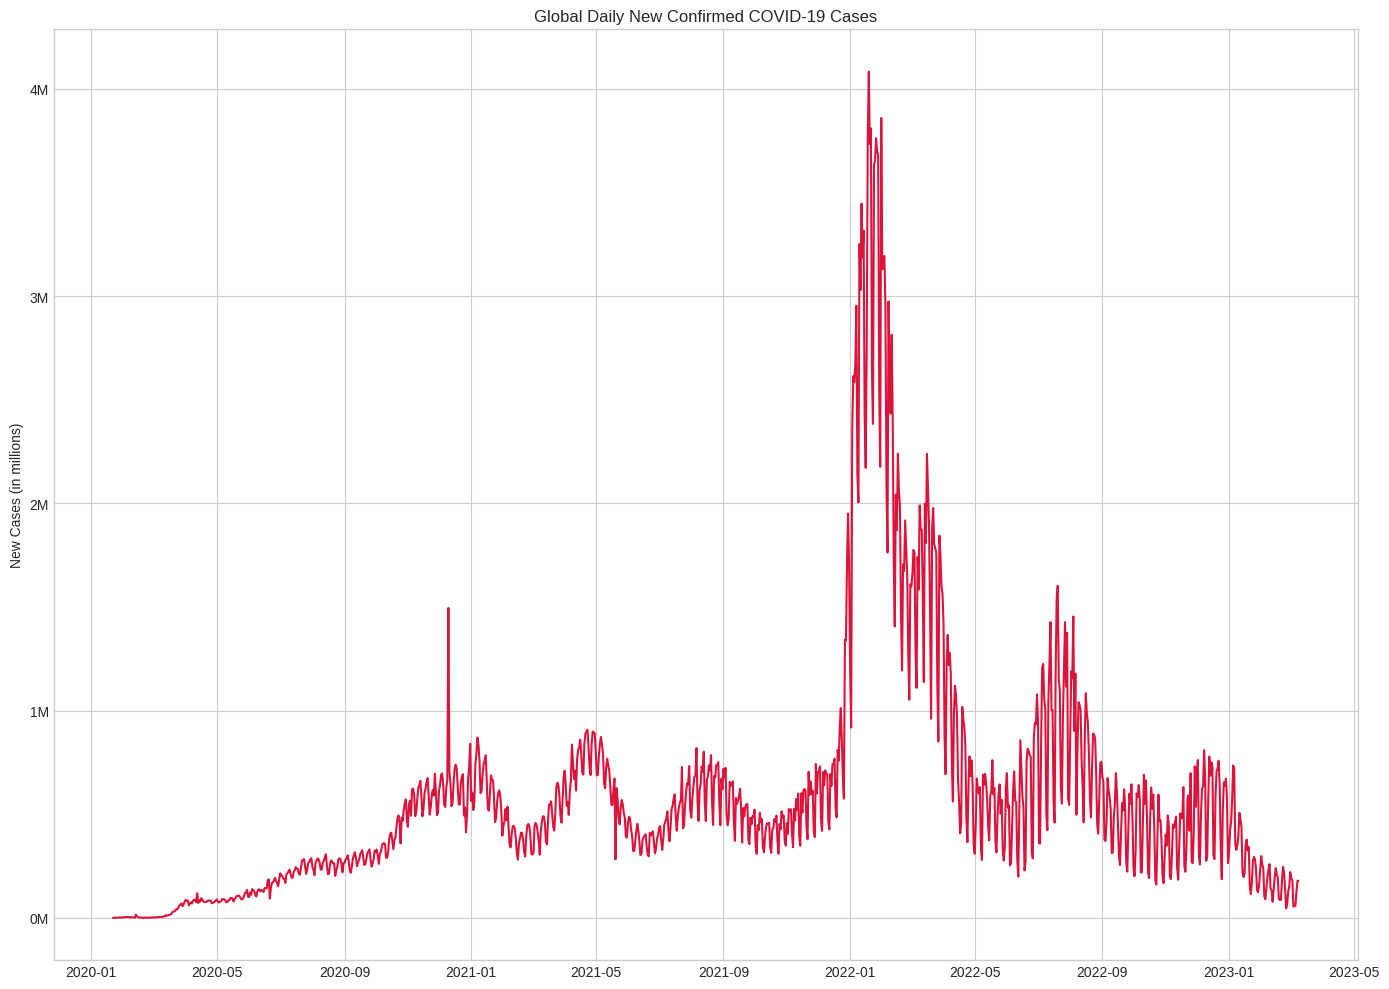

In [59]:
fig, ax = plt.subplots(figsize=(14, 10))

ax.plot(global_daily['Date'], global_daily['New_Cases'], color='crimson')
ax.set_title('Global Daily New Confirmed COVID-19 Cases')
ax.set_ylabel('New Cases (in millions)')
ax.set_yticks(np.arange(0, global_daily['New_Cases'].max(), 1_000_000))
ax.set_yticklabels([f"{int(y/1_000_000)}M" for y in np.arange(0, global_daily['New_Cases'].max(), 1_000_000)])
ax.grid(True)
plt.tight_layout()
plt.show()

#### Interpretation of Peaks and Waves

The global daily new cases series exhibits multiple pronounced peaks throughout the timeline:

- *Early 2020 (Jan–Apr)*: Global spread with cases plateauing at 0.1M, not forming a distinct peak. Mitigation stabilised counts without reducing them.

- *Mid‑2020 (May–Oct)*: Linear growth from 0.2M to 0.7M driven by testing expansion. No clear peak or trough appeared.

- *Delta (Nov 2020 – mid‑2021)*: Delta arrived at 0.8M. Repeated relaxation of measures prevented the usual post‑wave drop, pushing cases steadily to 1.3M.

- *Omicron (late 2021)*: Omicron appeared at 2.1M. Its expected spike and crash were absorbed into the existing linear trend. Further relaxations removed the post‑wave trough, so cases continued rising by 0.1M per month.

- *Decline (2022–2023)*: After the second Omicron wave, cases declined steadily through May 2023, driven by growing population immunity, seasonal changes, and stabilised public health responses.

These patterns reflect not only epidemiological dynamics but also:
- Changes in testing and reporting capacity (more tests = more reported cases)
- Policy interventions (lockdowns, border closures)
- Variant emergence and spread
- Vaccination rollout and coverage
- Seasonal effects (winter transmission is higher in temperate zones)
- Data reporting delays that create artificial smoothing and lag in the series

**Interpretation**:

The cumulative curve shows exponential growth early on, then a more linear phase. The daily new cases series is volatile and has visible peaks and hills. Those changes come from real waves, reporting backlogs, testing changes, and interventions. This is why the series is hard to model with a simple stationary process.

### 2.2. Summary Statistics

In [60]:
global_daily['New_Cases'].describe().apply(lambda x: format(x, 'f'))

count       1143.000000
mean      591924.402450
std       595647.939611
min            0.000000
25%       265196.000000
50%       472523.000000
75%       676774.000000
max      4083281.000000
Name: New_Cases, dtype: str

- The mean daily new cases is around 600k, but the standard deviation is large (~600k), indicating high variability.

- Minimum is 0 (early days), maximum exceeds 4 million.

### 2.3. Check for Outliers

We can inspect the series for extreme values using a boxplot or by identifying values beyond 3 times the standard deviations. However, given the nature of pandemic waves, these are not outliers but real events. We keep them.

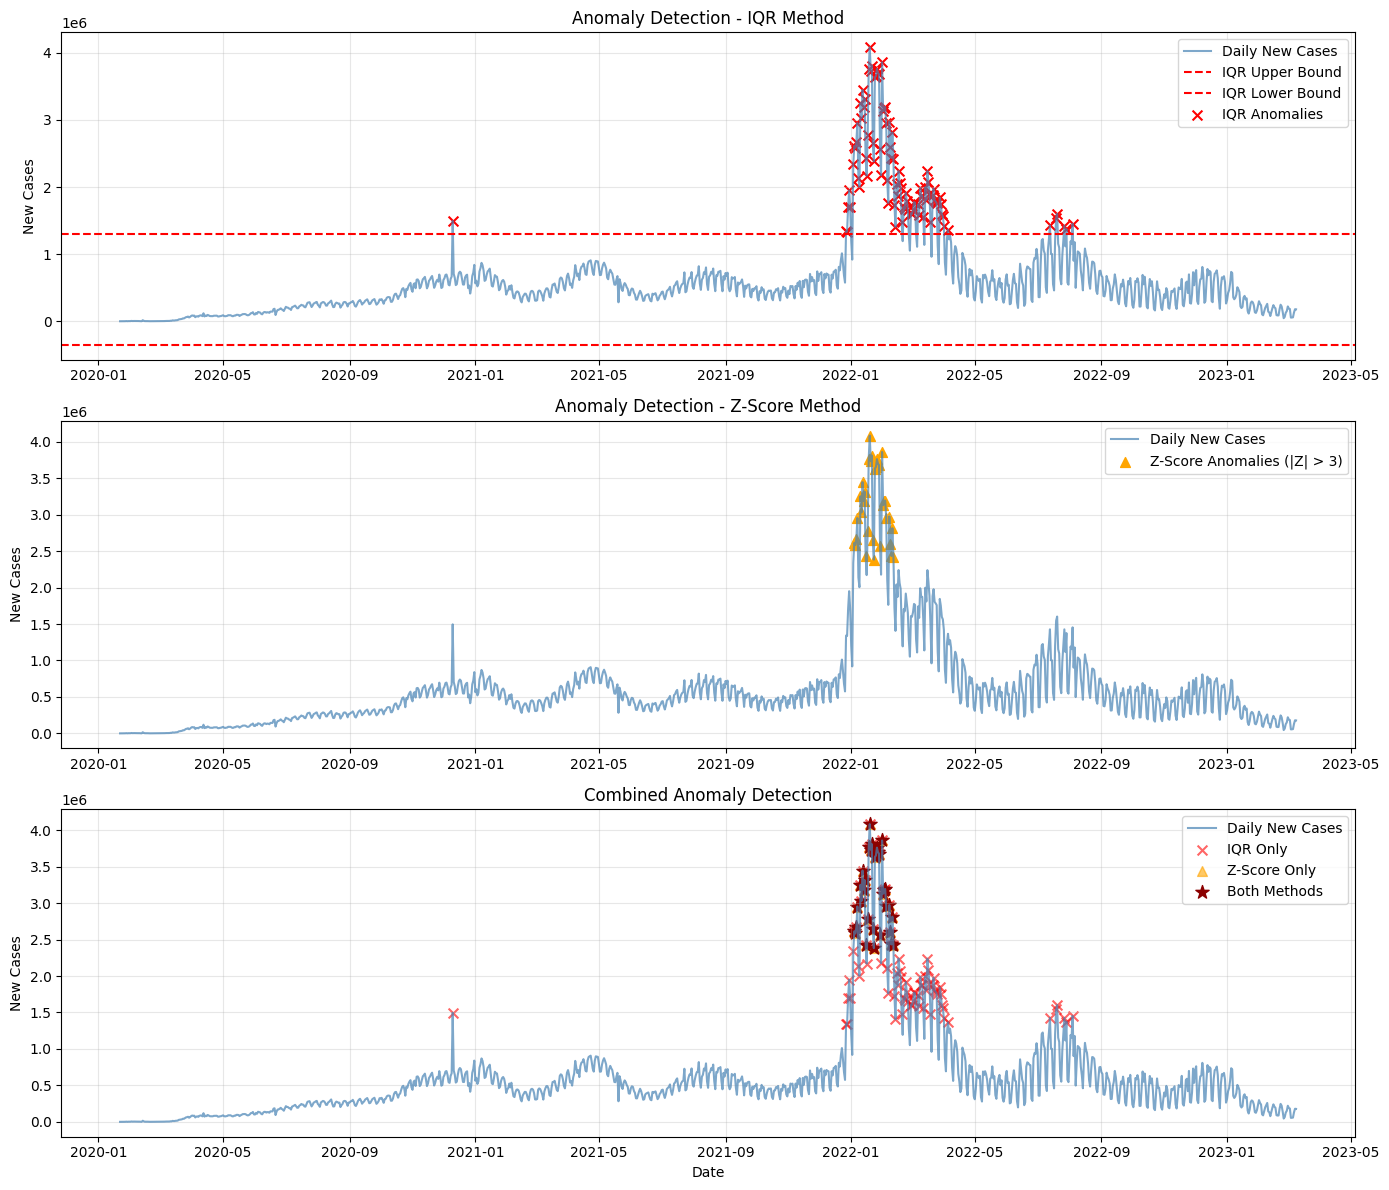

IQR Method: 93 anomalies detected (8.1%)
Z-Score Method: 33 anomalies detected (2.9%)
Agreement (both methods): 33 points (2.9%)

IQR bounds: [-352171, 1294141]


In [7]:
from scipy import stats

series_data = global_daily['New_Cases'].values

Q1 = np.percentile(series_data, 25)
Q3 = np.percentile(series_data, 75)
IQR = Q3 - Q1
lower_bound_iqr = Q1 - 1.5 * IQR
upper_bound_iqr = Q3 + 1.5 * IQR

z_scores = np.abs(stats.zscore(series_data))
z_threshold = 3
anomalies_z = z_scores > z_threshold

anomalies_iqr = (series_data < lower_bound_iqr) | (series_data > upper_bound_iqr)

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

axes[0].plot(global_daily['Date'], series_data, color='steelblue', alpha=0.7, label='Daily New Cases')
axes[0].axhline(y=upper_bound_iqr, color='red', linestyle='--', label='IQR Upper Bound')
axes[0].axhline(y=lower_bound_iqr, color='red', linestyle='--', label='IQR Lower Bound')
axes[0].scatter(global_daily['Date'][anomalies_iqr], series_data[anomalies_iqr], 
                color='red', s=50, marker='x', label='IQR Anomalies')
axes[0].set_title('Anomaly Detection - IQR Method')
axes[0].set_ylabel('New Cases')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(global_daily['Date'], series_data, color='steelblue', alpha=0.7, label='Daily New Cases')
axes[1].scatter(global_daily['Date'][anomalies_z], series_data[anomalies_z], 
                color='orange', s=50, marker='^', label=f'Z-Score Anomalies (|Z| > {z_threshold})')
axes[1].set_title('Anomaly Detection - Z-Score Method')
axes[1].set_ylabel('New Cases')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

both_anomalies = anomalies_iqr & anomalies_z
axes[2].plot(global_daily['Date'], series_data, color='steelblue', alpha=0.7, label='Daily New Cases')
axes[2].scatter(global_daily['Date'][anomalies_iqr], series_data[anomalies_iqr], 
                color='red', s=50, marker='x', alpha=0.6, label='IQR Only')
axes[2].scatter(global_daily['Date'][anomalies_z], series_data[anomalies_z], 
                color='orange', s=50, marker='^', alpha=0.6, label='Z-Score Only')
axes[2].scatter(global_daily['Date'][both_anomalies], series_data[both_anomalies], 
                color='darkred', s=100, marker='*', label='Both Methods')
axes[2].set_title('Combined Anomaly Detection')
axes[2].set_ylabel('New Cases')
axes[2].set_xlabel('Date')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_iqr_anomalies = anomalies_iqr.sum()
n_z_anomalies = anomalies_z.sum()
n_both = both_anomalies.sum()

print(f"IQR Method: {n_iqr_anomalies} anomalies detected ({n_iqr_anomalies/len(series_data)*100:.1f}%)")
print(f"Z-Score Method: {n_z_anomalies} anomalies detected ({n_z_anomalies/len(series_data)*100:.1f}%)")
print(f"Agreement (both methods): {n_both} points ({n_both/len(series_data)*100:.1f}%)")
print(f"\nIQR bounds: [{lower_bound_iqr:.0f}, {upper_bound_iqr:.0f}]")

### 2.4. Anomaly Detection

We identify anomalies using multiple statistical methods to understand which time points represent genuinely exceptional behavior.

## 3. Exploratory Data Analysis - Country Comparison

In [8]:
df_country = df_melt.groupby(['Date', 'Country/Region'])['Cumulative_Confirmed'].sum().reset_index()
df_pivot = df_country.pivot(index='Date', columns='Country/Region', values='Cumulative_Confirmed')

df_new = df_pivot.diff().fillna(0).clip(lower=0)

# Keep only 10 first countries with most data
TOTAL_CASES = df_pivot.iloc[-1].sort_values(ascending=False)
TOP_N = 10
TOP_COUNTRIES = TOTAL_CASES.head(TOP_N).index.tolist()

print(f"Top {TOP_N} countries by cumulative cases: {TOP_COUNTRIES}")
df_new_top = df_new[TOP_COUNTRIES]

Top 10 countries by cumulative cases: ['US', 'India', 'France', 'Germany', 'Brazil', 'Japan', 'Korea, South', 'Italy', 'United Kingdom', 'Russia']


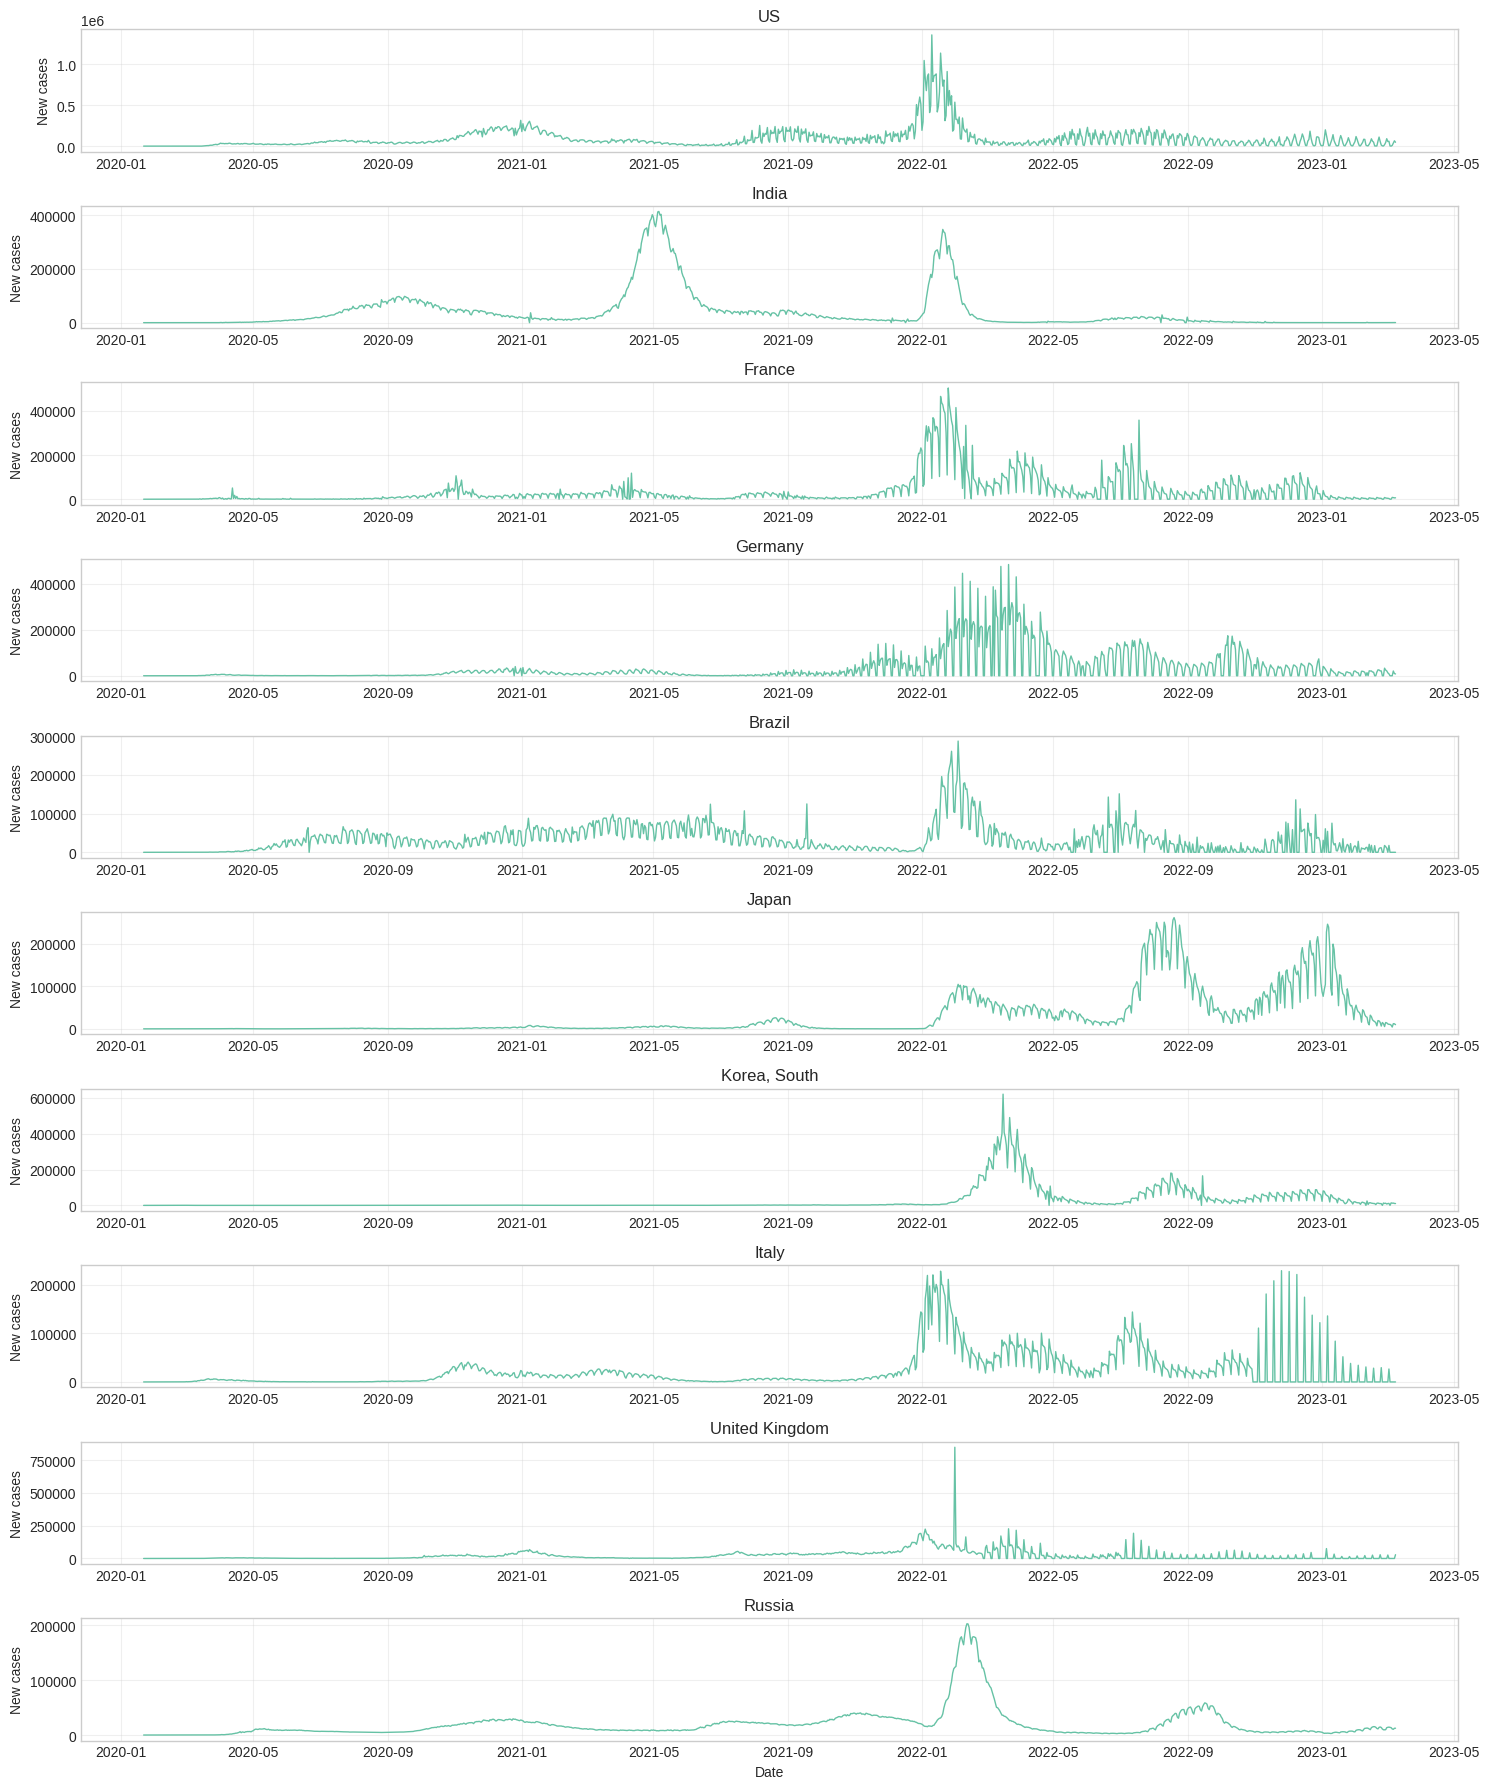

In [63]:
fig, axes = plt.subplots(TOP_N, 1, figsize=(15, 18), sharex = False)

for i, country in enumerate(TOP_COUNTRIES):
    axes[i].plot(df_new_top.index, df_new_top[country], linewidth=1)
    axes[i].set_ylabel('New cases')
    axes[i].set_title(country)
    axes[i].grid(True, alpha=0.3)

plt.xlabel('Date')
plt.tight_layout()
plt.show()

**Interpretation**:

Each country shows multiple waves, but their timings and amplitudes differ. The USA and India have the largest absolute scales. European countries show earlier peaks. This heterogeneity justifies treating them as separate series.

In [64]:
stats = df_new_top.describe().T[['mean', 'std', 'min', 'max']]
stats['cv'] = stats['std'] / stats['mean'] # coefficient of variation (PBS2 TMTC)
stats.sort_values('mean', ascending=False)

,mean,std,min,max,cv
Country/Region,,,,,
US,90819.390201,126544.552971,0.0,1354505.0,1.393365
India,39102.275591,71630.868857,0.0,414188.0,1.831885
France,35275.464567,65246.580443,0.0,503349.0,1.849631
Germany,33463.744532,64672.542586,0.0,484345.0,1.932615
Brazil,32460.251969,34613.058444,0.0,287149.0,1.066321
Japan,29151.737533,50986.907044,0.0,260999.0,1.749018
"Korea, South",26785.232721,63777.655959,0.0,621317.0,2.381075
Italy,22400.400700,36896.440199,0.0,229122.0,1.647133
United Kingdom,21583.239720,40847.343723,0.0,848169.0,1.892549


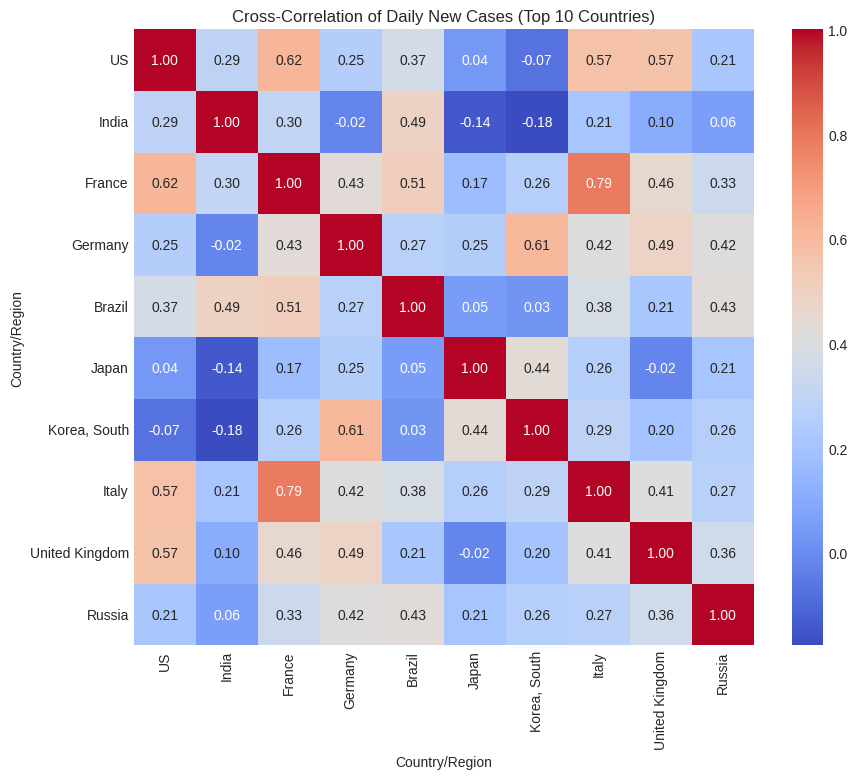

In [65]:
corr_matrix = df_new_top.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Cross-Correlation of Daily New Cases (Top 10 Countries)')
plt.show()

**Interpretation**:

Most correlations are positive (0.2 - 0.6), indicating a degree of synchrony. However, even though we expected regional correlations (i.e. neighbouring countries should correlate strongly), France and Italy are the only neighbours that seem linked in the number of new cases. This might indicate relations between far apart countries, and the overall access to long-distance modes of transportation.

### Multivariate Analysis with Functional Principal Component Analysis (FPCA)

Functional Principal Component Analysis extends classical PCA to functional data, treating each country's daily series as a smooth function. This allows us to identify the main modes of variation across countries.

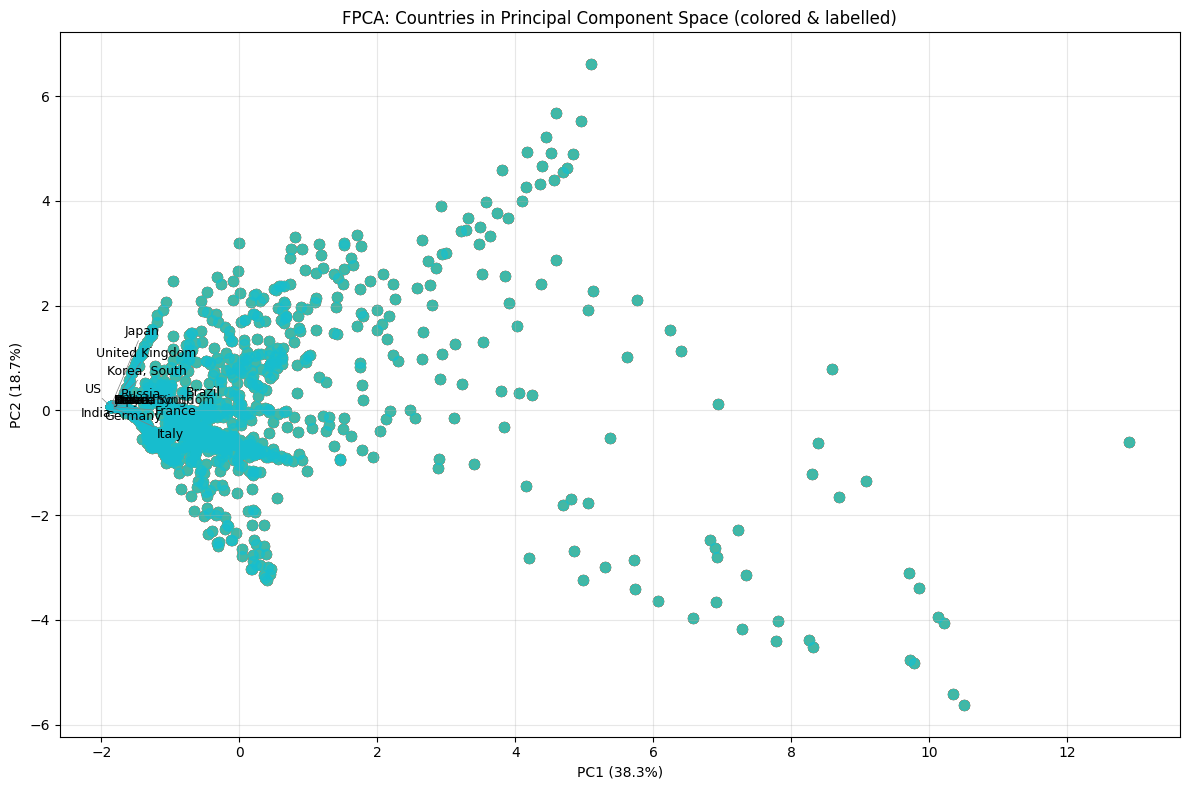

Variance explained by first 3 components: 67.5%

Principal Component Loadings (first 3):
US: PC1=0.353, PC2=-0.287, PC3=0.344
India: PC1=0.163, PC2=-0.476, PC3=-0.399
France: PC1=0.436, PC2=-0.108, PC3=0.027
Germany: PC1=0.348, PC2=0.330, PC3=0.080
Brazil: PC1=0.316, PC2=-0.268, PC3=-0.500
Japan: PC1=0.148, PC2=0.425, PC3=-0.341
Korea, South: PC1=0.213, PC2=0.549, PC3=-0.098
Italy: PC1=0.411, PC2=-0.026, PC3=0.083
United Kingdom: PC1=0.341, PC2=-0.028, PC3=0.515
Russia: PC1=0.292, PC2=0.126, PC3=-0.261


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Your existing data preparation
countries_for_fpca = TOP_COUNTRIES

standardized_data = (df_new_top[countries_for_fpca] - df_new_top[countries_for_fpca].mean()) / df_new_top[countries_for_fpca].std()
standardized_data_filled = standardized_data.fillna(0)

pca = PCA(n_components=3)
pca_scores = pca.fit_transform(standardized_data_filled)

explained_var = pca.explained_variance_ratio_
cumsum_var = np.cumsum(explained_var)

# ---- IMPROVED PLOTTING ----
fig, ax = plt.subplots(figsize=(12, 8))

# Use a colormap to give each country a distinct color
colors = plt.cm.tab10(np.linspace(0, 1, len(countries_for_fpca)))

# Scatter points with colors
for i, country in enumerate(countries_for_fpca):
    ax.scatter(pca_scores[:, 0], pca_scores[:, 1],
               c=[colors[i]], alpha=0.7, s=50, label=country)   # now color is used

# Add country labels next to each point (with a slight offset)
for i, country in enumerate(countries_for_fpca):
    ax.text(pca_scores[i, 0] + 0.05, pca_scores[i, 1] + 0.05,
            country, fontsize=9, alpha=0.8)

# If you have many countries and labels overlap, install adjustText:
from adjustText import adjust_text
texts = []
for i, country in enumerate(countries_for_fpca):
    texts.append(ax.text(pca_scores[i, 0], pca_scores[i, 1], country, fontsize=9))
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=0.5))

# Set labels and title
ax.set_xlabel(f'PC1 ({explained_var[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({explained_var[1]*100:.1f}%)')
ax.set_title('FPCA: Countries in Principal Component Space (colored & labelled)')
ax.grid(True, alpha=0.3)

# Optional: add a legend (can be cluttered if many countries – comment out if needed)
# ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

# Print variance and loadings as before
print(f"Variance explained by first 3 components: {cumsum_var[2]*100:.1f}%")
print(f"\nPrincipal Component Loadings (first 3):")
loadings = pca.components_[:3].T
for i, country in enumerate(countries_for_fpca):
    print(f"{country}: PC1={loadings[i,0]:.3f}, PC2={loadings[i,1]:.3f}, PC3={loadings[i,2]:.3f}")

In [14]:
countries_for_fpca = TOP_COUNTRIES

standardized_data = (df_new_top[countries_for_fpca] - df_new_top[countries_for_fpca].mean()) / df_new_top[countries_for_fpca].std()
standardized_data_filled = standardized_data.fillna(0)

pca = PCA(n_components=10)
pca_scores = pca.fit_transform(standardized_data_filled)

explained_var = pca.explained_variance_ratio_
cumsum_var = np.cumsum(explained_var)

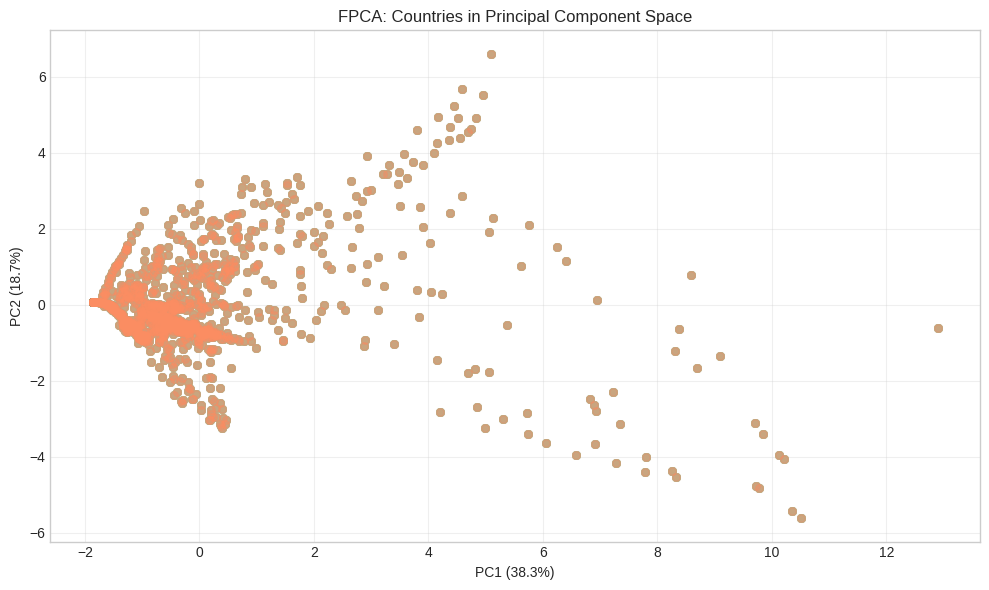

Variance explained by first 3 components: 67.5%

Principal Component Loadings (first 3):
US: PC1=0.353, PC2=-0.287, PC3=0.344
India: PC1=0.163, PC2=-0.476, PC3=-0.399
France: PC1=0.436, PC2=-0.108, PC3=0.027
Germany: PC1=0.348, PC2=0.330, PC3=0.080
Brazil: PC1=0.316, PC2=-0.268, PC3=-0.500
Japan: PC1=0.148, PC2=0.425, PC3=-0.341
Korea, South: PC1=0.213, PC2=0.549, PC3=-0.098
Italy: PC1=0.411, PC2=-0.026, PC3=0.083
United Kingdom: PC1=0.341, PC2=-0.028, PC3=0.515
Russia: PC1=0.292, PC2=0.126, PC3=-0.261


In [67]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(countries_for_fpca)))
for i, country in enumerate(countries_for_fpca):
    ax.scatter(pca_scores[:, 0], pca_scores[:, 1], alpha=0.5, s=30)

ax.set_xlabel(f'PC1 ({explained_var[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({explained_var[1]*100:.1f}%)')
ax.set_title('FPCA: Countries in Principal Component Space')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Variance explained by first 3 components: {cumsum_var[2]*100:.1f}%")
print(f"\nPrincipal Component Loadings (first 3):")
loadings = pca.components_[:3].T
for i, country in enumerate(countries_for_fpca):
    print(f"{country}: PC1={loadings[i,0]:.3f}, PC2={loadings[i,1]:.3f}, PC3={loadings[i,2]:.3f}")

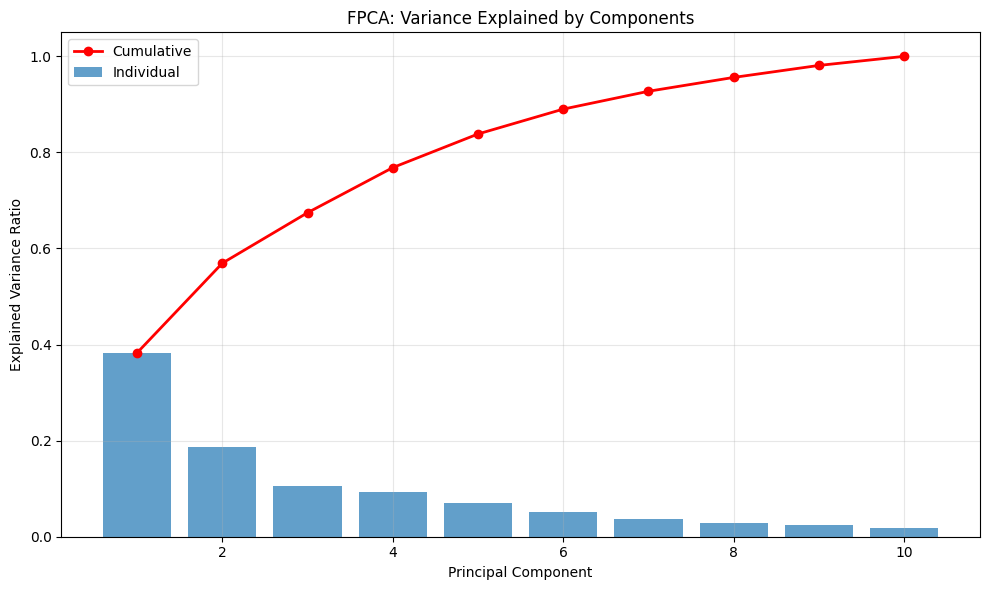

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(range(1, len(explained_var) + 1), explained_var, alpha=0.7, label='Individual')
ax.plot(range(1, len(cumsum_var) + 1), cumsum_var, 'ro-', linewidth=2, label='Cumulative')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('FPCA: Variance Explained by Components')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Temporal Structure Analysis

### 4.1. Stationarity

Stationarity means that the statistical behavior of a series does not change in a strong way over time: the mean, variance, and autocorrelation structure are roughly stable. Epidemic series usually violate this because they contain waves, reporting changes, and policy shifts.

We compare the original series with several transformed versions and apply two complementary tests:

- ADF: null hypothesis is that the series has a unit root, so it is non-stationary.
- KPSS: null hypothesis is that the series is stationary.

For the original global daily new confirmed cases series, the result should still point to non-stationarity. The transformed series are only there to show how differencing or logging changes the conclusion.

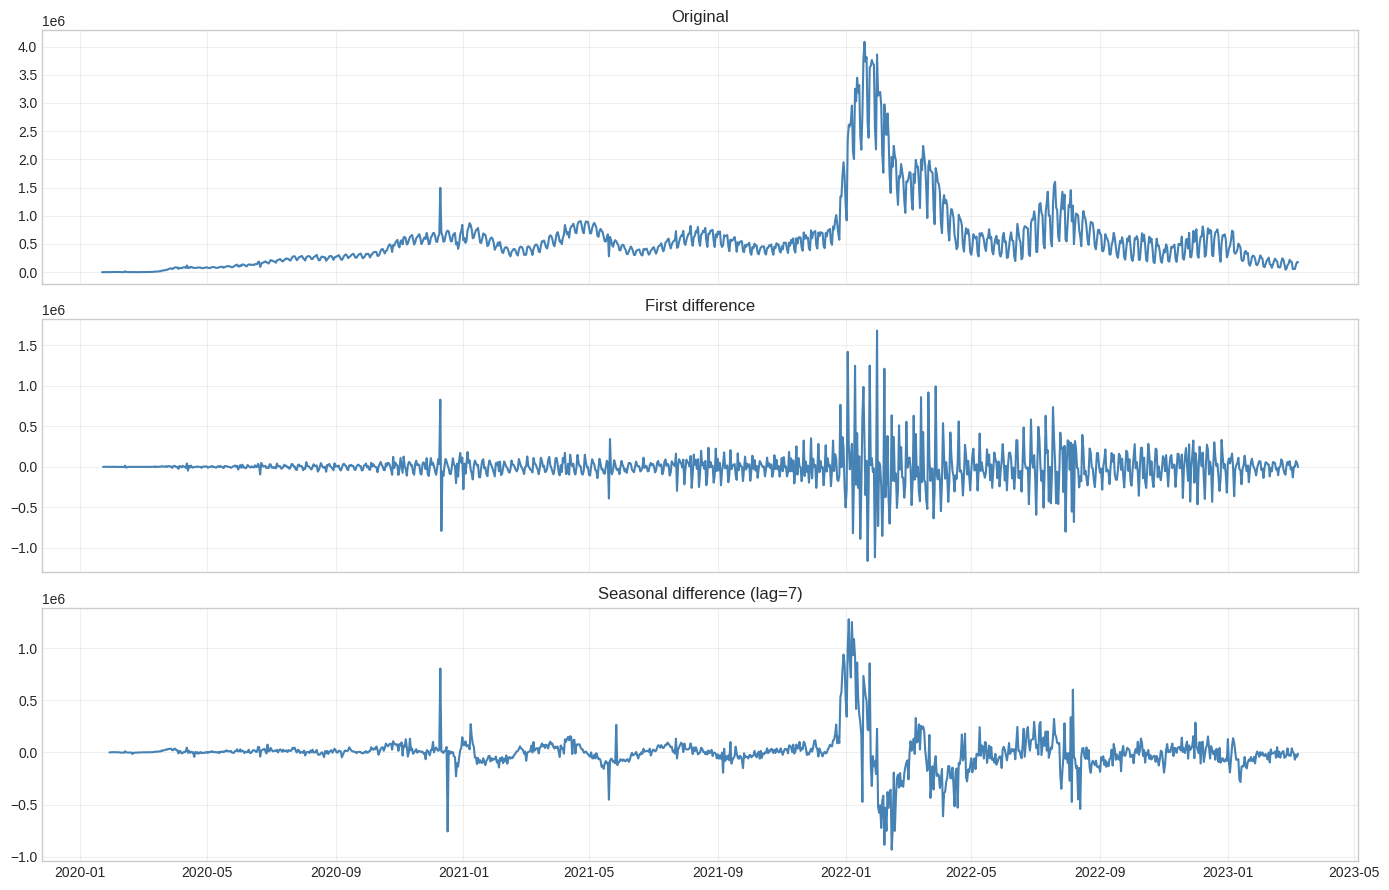

--- Original ---
ADF Statistic: -3.0301
ADF p-value: 0.1239
ADF Critical Value (1%): -3.9669
ADF Critical Value (5%): -3.4144
ADF Critical Value (10%): -3.1294
KPSS Statistic: 0.4560
KPSS p-value: 0.0100

--- First difference ---
ADF Statistic: -6.6904
ADF p-value: 0.0000
ADF Critical Value (1%): -3.9669
ADF Critical Value (5%): -3.4144
ADF Critical Value (10%): -3.1294
KPSS Statistic: 0.0314
KPSS p-value: 0.1000

--- Seasonal difference (lag=7) ---
ADF Statistic: -7.3021
ADF p-value: 0.0000
ADF Critical Value (1%): -3.9669
ADF Critical Value (5%): -3.4144
ADF Critical Value (10%): -3.1294
KPSS Statistic: 0.0338
KPSS p-value: 0.1000



/tmp/ipykernel_49512/3435235806.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_res = kpss(s, regression='ct', nlags='auto')
/tmp/ipykernel_49512/3435235806.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_res = kpss(s, regression='ct', nlags='auto')
/tmp/ipykernel_49512/3435235806.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_res = kpss(s, regression='ct', nlags='auto')


In [69]:
def stationarity_report(series, name):
    s = series.dropna()
    print(f'--- {name} ---')
    adf_res = adfuller(s, regression='ct', autolag='AIC')
    print(f'ADF Statistic: {adf_res[0]:.4f}')
    print(f'ADF p-value: {adf_res[1]:.4f}')
    for key, value in adf_res[4].items():
        print(f'ADF Critical Value ({key}): {value:.4f}')
    kpss_res = kpss(s, regression='ct', nlags='auto')
    print(f'KPSS Statistic: {kpss_res[0]:.4f}')
    print(f'KPSS p-value: {kpss_res[1]:.4f}')
    print()


ts_orig = global_daily.set_index('Date')['New_Cases'].asfreq('D')
ts_diff1 = ts_orig.diff(1)
ts_seasonal = ts_orig.diff(7)

series_list = [
    (ts_orig, 'Original'),
    (ts_diff1, 'First difference'),
    (ts_seasonal, 'Seasonal difference (lag=7)')
]

fig, axes = plt.subplots(len(series_list), 1, figsize=(14, 3 * len(series_list)), sharex=True)
for i, (series, name) in enumerate(series_list):
    axes[i].plot(series.index, series.values, color='steelblue')
    axes[i].set_title(name)
    axes[i].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for series, name in series_list:
    stationarity_report(series, name)

**Conclusion**: the original series is non-stationary.

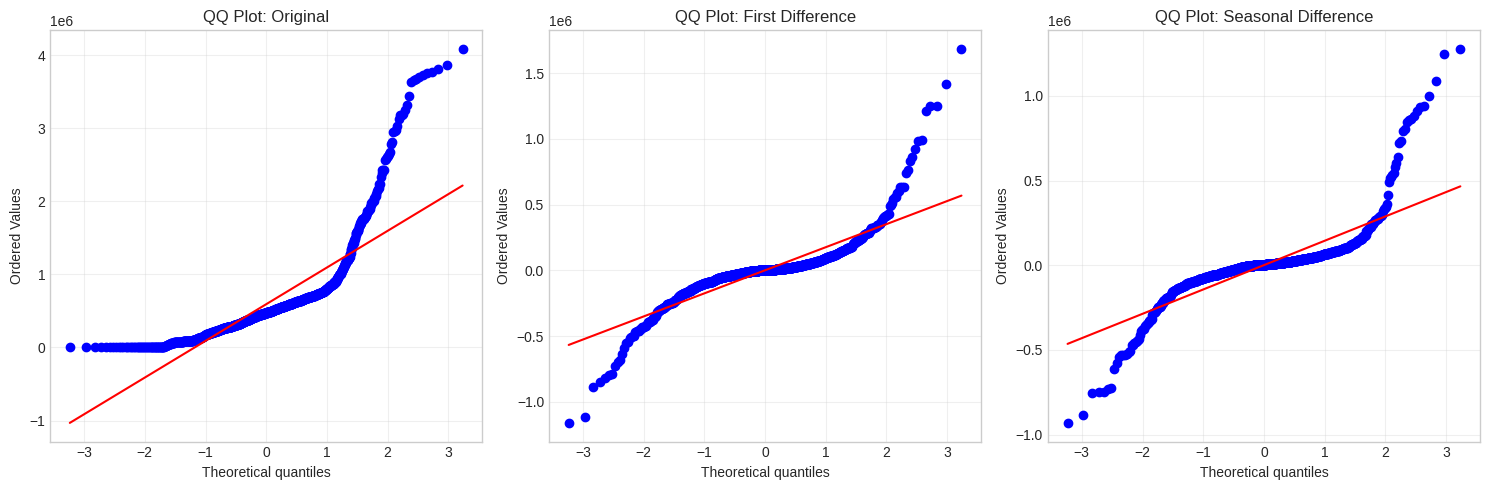

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (series, name) in enumerate([(ts_orig, 'Original'), 
                                      (ts_diff1, 'First Difference'), 
                                      (ts_seasonal, 'Seasonal Difference')]):
    series_clean = series.dropna()
    probplot(series_clean, dist="norm", plot=axes[i])
    axes[i].set_title(f'QQ Plot: {name}')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.1.1. QQ Plot and Normality Assessment

To assess whether the residuals or differenced series follow a normal distribution, we generate QQ plots comparing the quantiles of our data to theoretical normal quantiles.

### 4.2. Trend and Seasonality Decomposition

We use ```seasonal_decompose``` to separate the series into trend, seasonal, and residual parts. The weekly seasonal component is easier to interpret after decomposition because the long-term trend is removed from it.

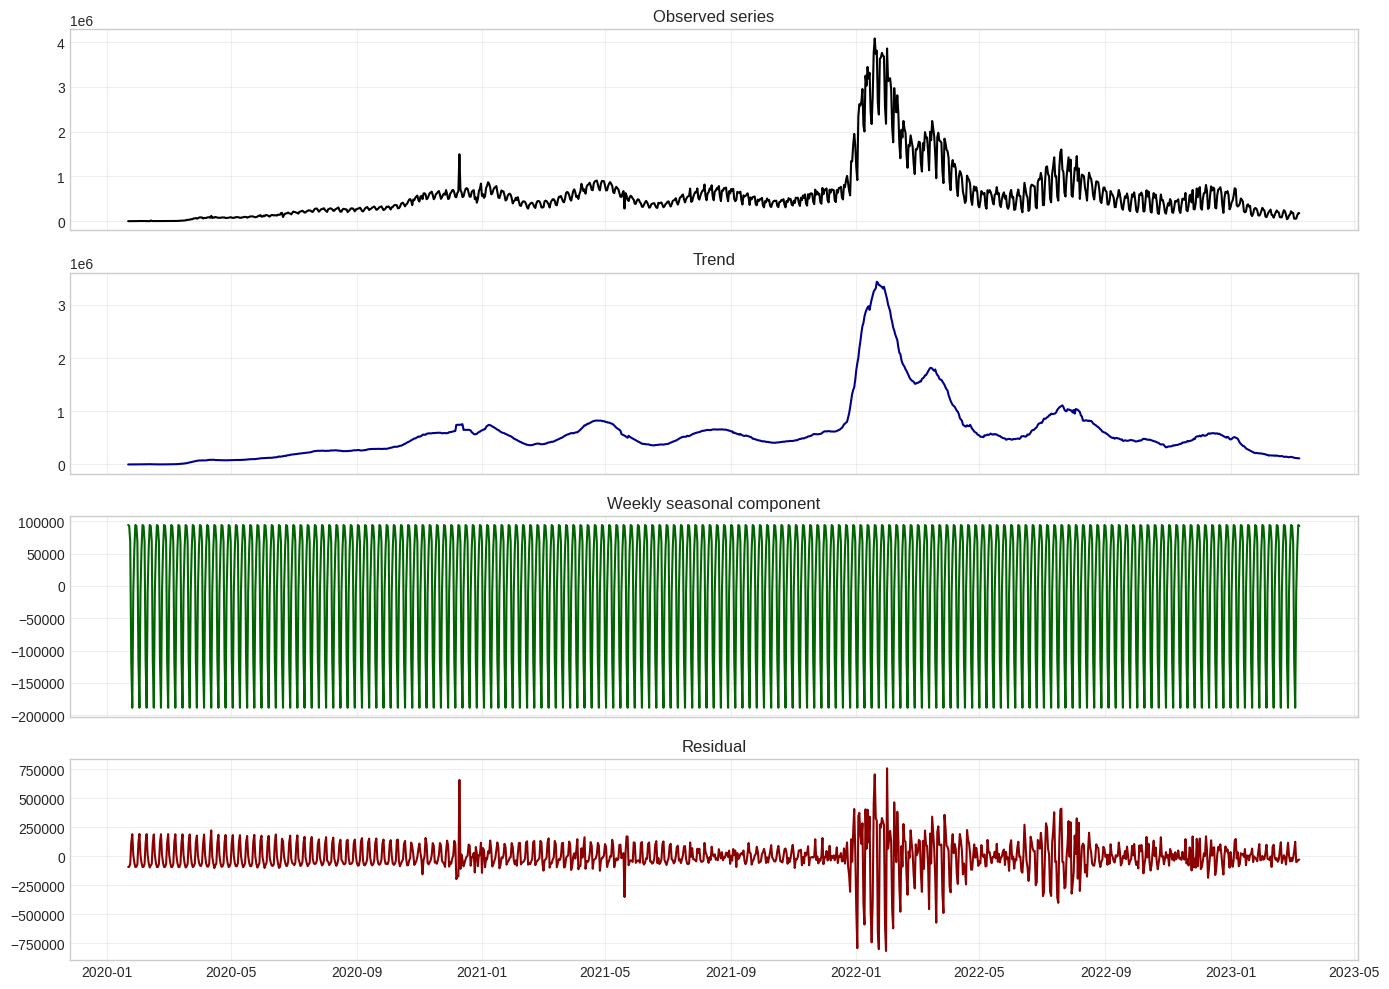

In [71]:
ts = global_daily.set_index('Date')['New_Cases'].asfreq('D')
decomposition = seasonal_decompose(ts, model='additive', period=7, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(ts.index, ts.values, color='black')
axes[0].set_title('Observed series')
axes[1].plot(decomposition.trend.index, decomposition.trend.values, color='darkblue')
axes[1].set_title('Trend')
axes[2].plot(decomposition.seasonal.index, decomposition.seasonal.values, color='darkgreen')
axes[2].set_title('Weekly seasonal component')
axes[3].plot(decomposition.resid.index, decomposition.resid.values, color='darkred')
axes[3].set_title('Residual')
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

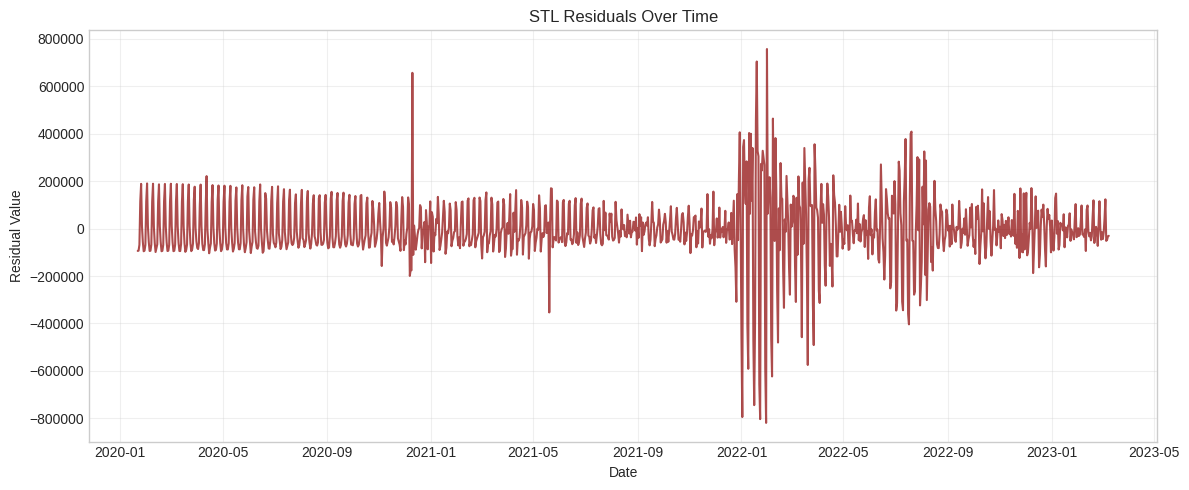

In [72]:
residuals = decomposition.resid.dropna()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(residuals.index, residuals.values, color='darkred', alpha=0.7)
ax.set_title('STL Residuals Over Time')
ax.set_ylabel('Residual Value')
ax.set_xlabel('Date')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

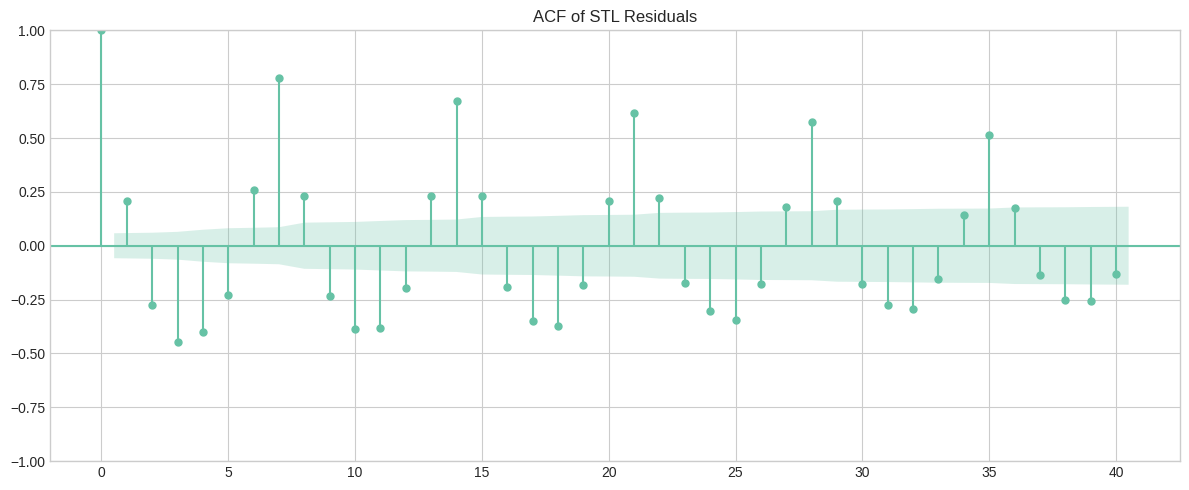

Residuals Mean: -1.18e+02
Residuals Std Dev: 1.35e+05
Residuals Min: -8.19e+05
Residuals Max: 7.57e+05


In [73]:
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(residuals, lags=40, ax=ax)
ax.set_title('ACF of STL Residuals')

plt.tight_layout()
plt.show()

print(f"Residuals Mean: {residuals.mean():.2e}")
print(f"Residuals Std Dev: {residuals.std():.2e}")
print(f"Residuals Min: {residuals.min():.2e}")
print(f"Residuals Max: {residuals.max():.2e}")

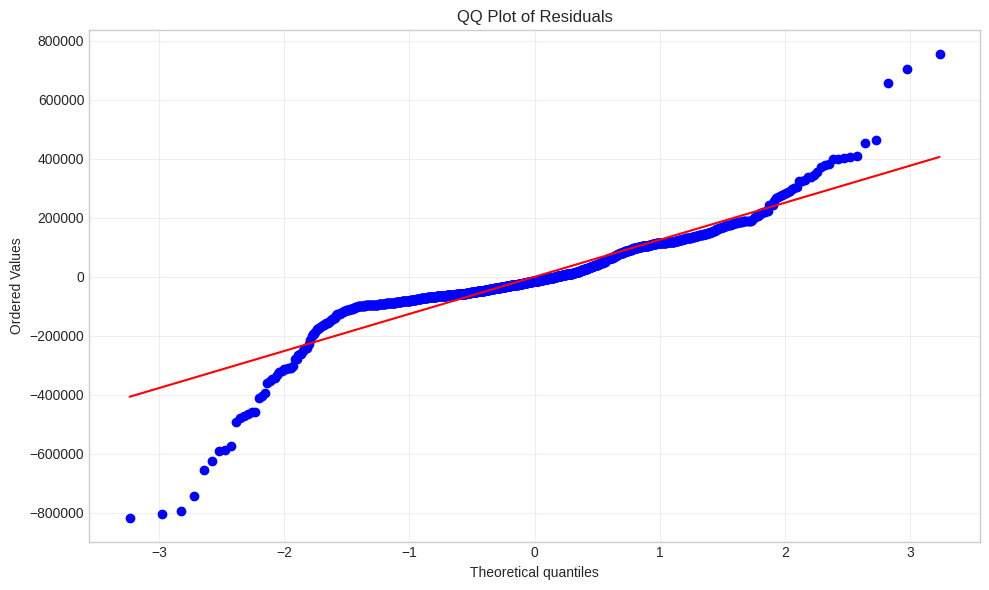

In [74]:
fig, ax = plt.subplots(figsize=(10, 6))

probplot(residuals.values, dist="norm", plot=ax)
ax.set_title('QQ Plot of Residuals')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

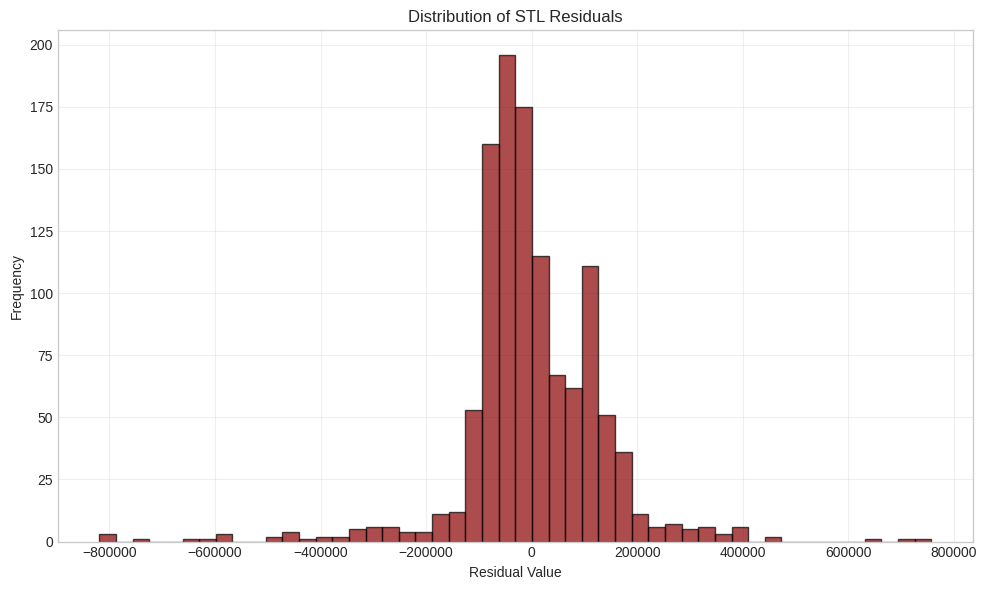

In [75]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(residuals.values, bins=50, edgecolor='black', alpha=0.7, color='darkred')
ax.set_title('Distribution of STL Residuals')
ax.set_xlabel('Residual Value')
ax.set_ylabel('Frequency')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### STL Residuals Characteristics

Examining the residuals from STL decomposition helps us understand the remaining structure after removing trend and seasonality.

### 4.2.1. Calendar Season Effects

Weekly seasonality is not the same thing as winter or summer. To test calendar seasons, we group daily values by meteorological season and compare the average levels across years. This is only a descriptive check, but it helps us see whether the epidemic behaved differently in winter, spring, summer, or autumn.

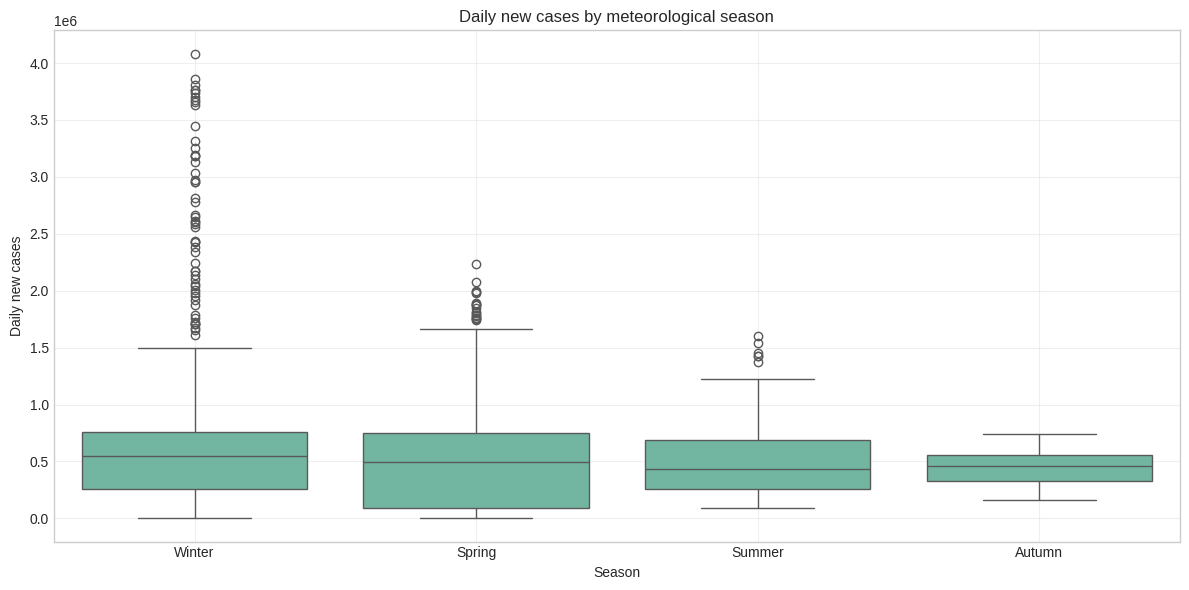

,Year,Season,New_Cases
0,2020,Autumn,4.163395e+05
1,2020,Spring,6.627492e+04
2,2020,Summer,2.103481e+05
3,2020,Winter,2.920264e+05
4,2021,Autumn,4.926264e+05
5,2021,Spring,6.158875e+05
6,2021,Summer,5.113538e+05
7,2021,Winter,6.268274e+05
8,2022,Autumn,4.385174e+05
9,2022,Spring,1.008454e+06


In [76]:
season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}

season_df = global_daily.copy()
season_df['Season'] = season_df['Date'].dt.month.map(season_map)
season_df['Year'] = season_df['Date'].dt.year
season_summary = season_df.groupby(['Year', 'Season'])['New_Cases'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=season_df, x='Season', y='New_Cases', order=['Winter', 'Spring', 'Summer', 'Autumn'], ax=ax)
ax.set_title('Daily new cases by meteorological season')
ax.set_ylabel('Daily new cases')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

season_summary

### 4.3. Autocorrelation and Partial Autocorrelation

We plot ACF and PACF to identify potential AR and MA orders for ARIMA.

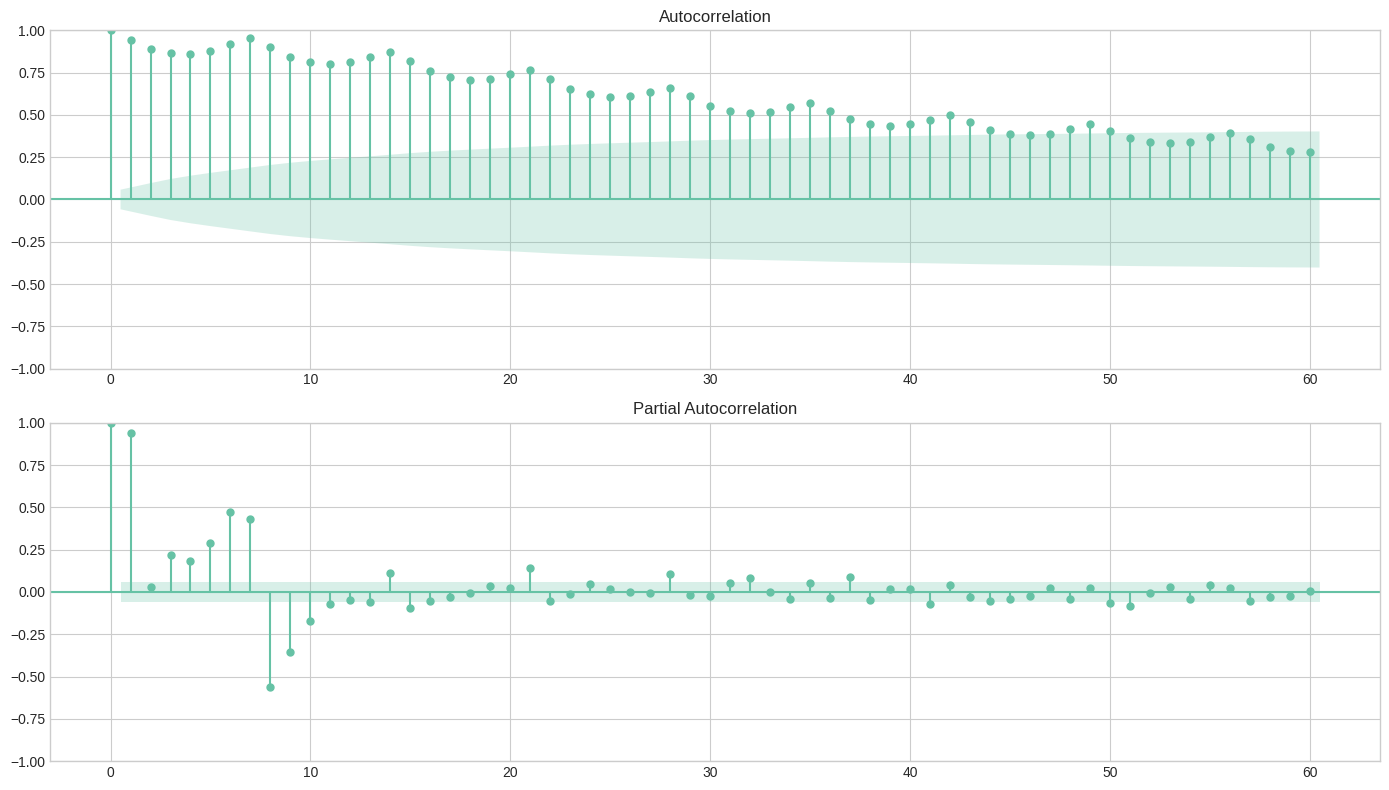

In [77]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(ts.dropna(), lags=60, ax=ax1)
plot_pacf(ts.dropna(), lags=60, ax=ax2, method='ywm')
plt.tight_layout()
plt.show()

**Observations**:

- ACF decays slowly, which is a sign that the raw series is not stationary.
- PACF is more informative after the main trend has been removed, because the original series contains strong non-stationary structure.
- Weekly seasonality is visible because the data are reported on a daily calendar: the same weekday often behaves similarly across weeks.

The seasonal component from decomposition is not meant to reproduce the trend. It isolates the repeating weekly pattern after removing the long-term movement. That is why we inspect it separately instead of expecting one plot to show everything at once.

### 4.4. Temporal Characteristics per Country

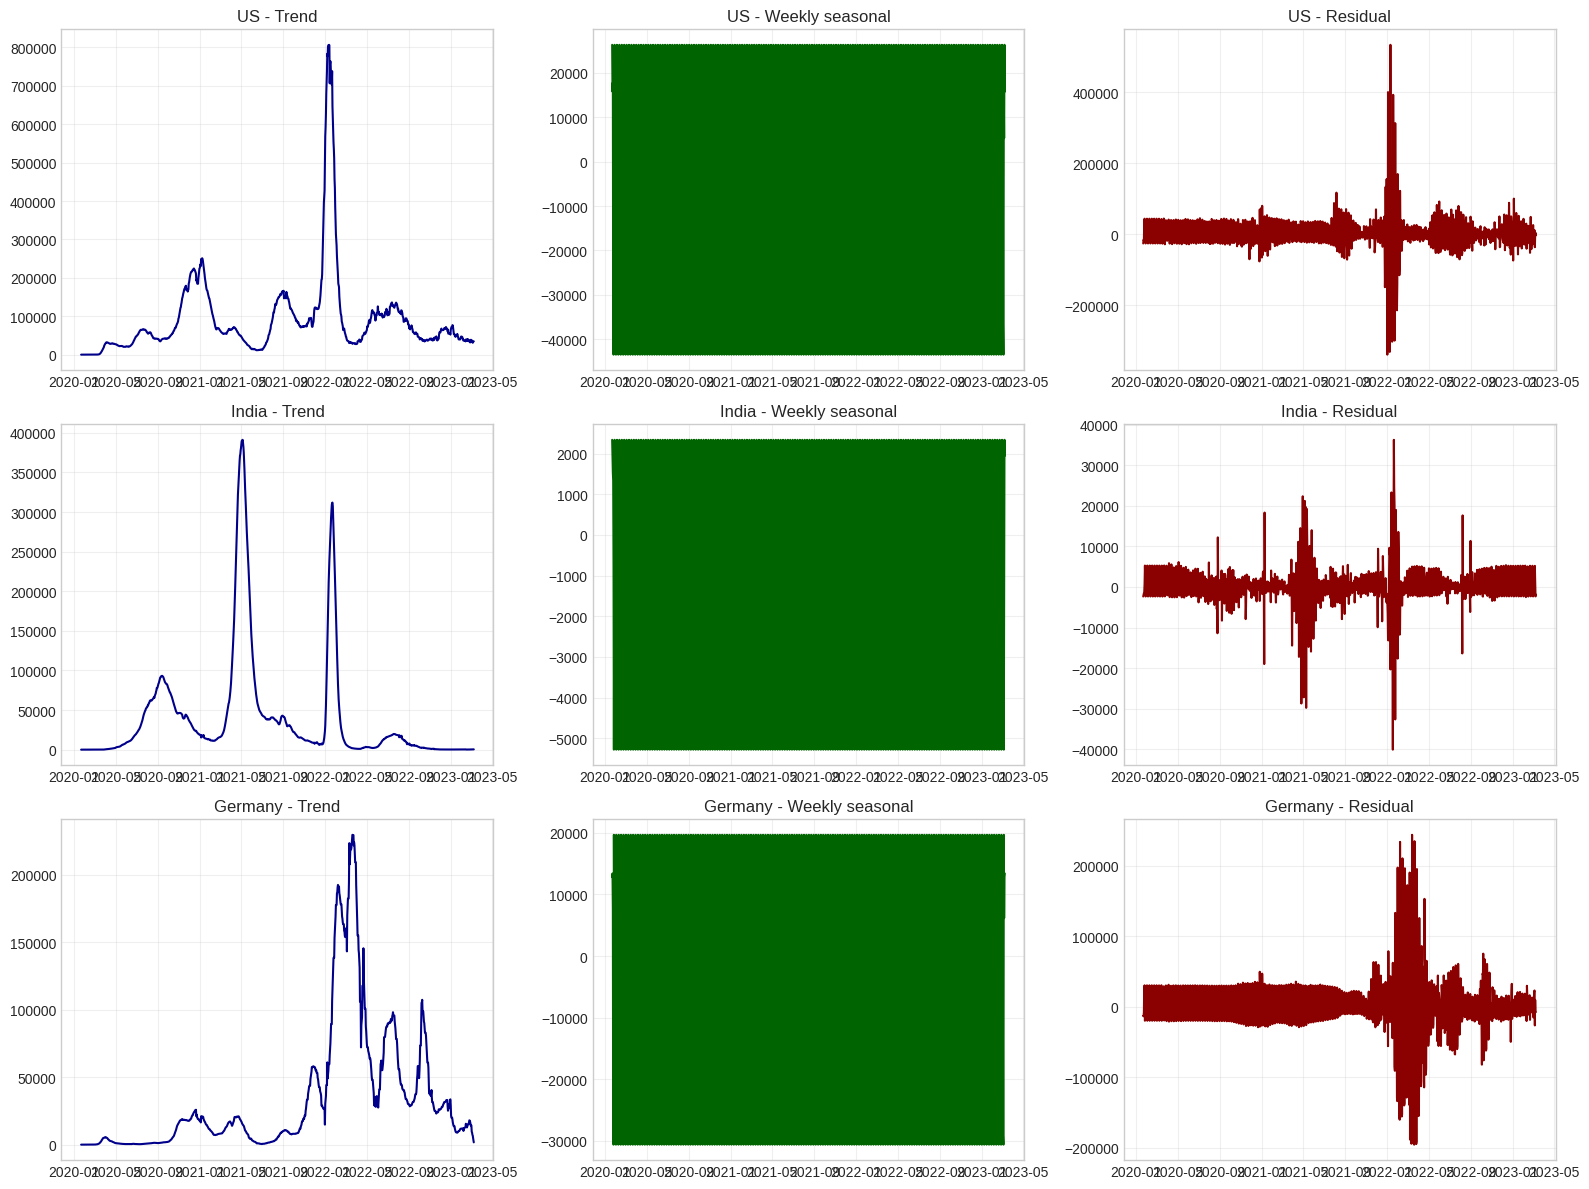

In [78]:
DECOMP_COUNTRIES = ['US', 'India', 'Germany']
fig, axes = plt.subplots(len(DECOMP_COUNTRIES), 3, figsize=(16, 4 * len(DECOMP_COUNTRIES)))

for i, country in enumerate(DECOMP_COUNTRIES):
    if country not in df_new_top.columns:
        continue
    series = df_new_top[country].dropna().asfreq('D')
    decomp = seasonal_decompose(series, model='additive', period=7, extrapolate_trend='freq')

    axes[i, 0].plot(decomp.trend.index, decomp.trend.values, color='darkblue')
    axes[i, 0].set_title(f'{country} - Trend')
    axes[i, 1].plot(decomp.seasonal.index, decomp.seasonal.values, color='darkgreen')
    axes[i, 1].set_title(f'{country} - Weekly seasonal')
    axes[i, 2].plot(decomp.resid.index, decomp.resid.values, color='darkred')
    axes[i, 2].set_title(f'{country} - Residual')

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

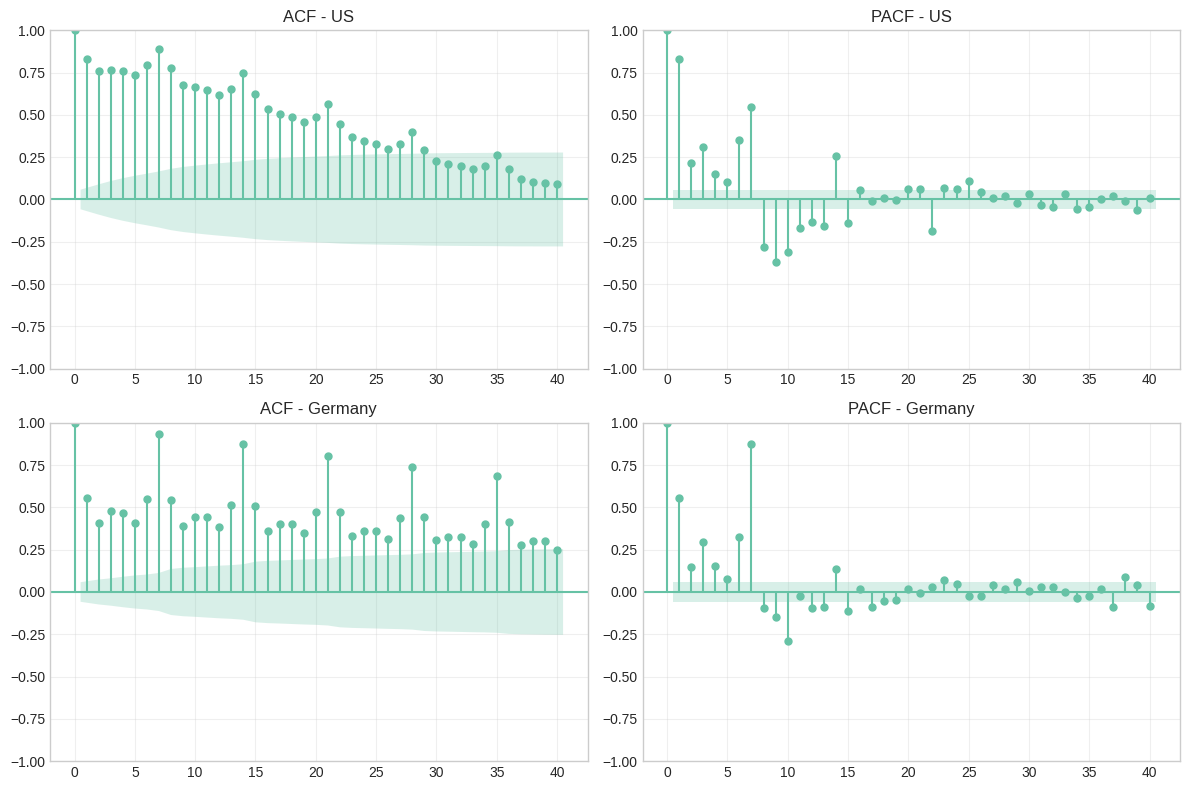

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

country1 = 'US'
country2 = 'Germany' if 'Germany' in df_new_top.columns else TOP_COUNTRIES[1]

plot_acf(df_new_top[country1].dropna(), lags=40, ax=axes[0, 0], title=f'ACF - {country1}')
plot_pacf(df_new_top[country1].dropna(), lags=40, ax=axes[0, 1], title=f'PACF - {country1}', method='ywm')
plot_acf(df_new_top[country2].dropna(), lags=40, ax=axes[1, 0], title=f'ACF - {country2}')
plot_pacf(df_new_top[country2].dropna(), lags=40, ax=axes[1, 1], title=f'PACF - {country2}', method='ywm')

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Model Selection and Justification

We will compare three baseline models and a more sophisticated one:

- Naive (persistence) forecast: uses the last observed value as the forecast for all future periods. This serves as a simple benchmark.

- Seasonal Naive: uses the value from the same day of the previous week. This captures weekly seasonality.

- ARIMA: we will fit an ARIMA model with seasonal component (SARIMA) using the auto_arima approach (not available in statsmodels, so we manually select orders based on ACF/PACF and grid search).

We choose these because:

- They are interpretable and widely used.

- They avoid over‑complicated deep learning methods, which often require more data and are harder to tune.

- They provide a good baseline for forecasting infectious disease data, which is known to be non‑stationary and seasonal.

Assumptions:

- The series has a linear trend and stable seasonality (not always true, but we accept this simplification).

- We assume that the future will resemble the recent past, i.e., no major new interventions or variants that change the dynamics abruptly. This is a major limitation.

### 5.1. Train/Test Split

We reserve the last 30 days as the test set to evaluate forecast performance.

In [80]:
train = ts.iloc[:-30]
test = ts.iloc[-30:]
print(f"Train: {train.index.min()} to {train.index.max()} ({len(train)} days)")
print(f"Test: {test.index.min()} to {test.index.max()} ({len(test)} days)")

Train: 2020-01-22 00:00:00 to 2023-02-07 00:00:00 (1113 days)
Test: 2023-02-08 00:00:00 to 2023-03-09 00:00:00 (30 days)


## 6. Model Implementation and Evaluation

### 6.1. Naive Forecast

In [81]:
last_train = train.iloc[-1]
naive_forecast = pd.Series([last_train] * len(test), index=test.index)

mae_naive = mean_absolute_error(test, naive_forecast)
rmse_naive = np.sqrt(mean_squared_error(test, naive_forecast))
print(f"Naive MAE: {mae_naive:.0f}, RMSE: {rmse_naive:.0f}")

Naive MAE: 63625, RMSE: 79281


### 6.2. Seasonal Naive

In [82]:
# We need to align: for each test date, take the train value from the same weekday 7 days prior.
# Because test starts right after train, the corresponding train index is test index - 7 days.
seasonal_naive_forecast = []
for date in test.index:
    prev_date = date - timedelta(days=7)
    if prev_date in train.index:
        seasonal_naive_forecast.append(train.loc[prev_date])
    else:
        # fallback to last available
        seasonal_naive_forecast.append(train.iloc[-1])
seasonal_naive_forecast = pd.Series(seasonal_naive_forecast, index=test.index)

mae_snaive = mean_absolute_error(test, seasonal_naive_forecast)
rmse_snaive = np.sqrt(mean_squared_error(test, seasonal_naive_forecast))
print(f"Seasonal Naive MAE: {mae_snaive:.0f}, RMSE: {rmse_snaive:.0f}")

Seasonal Naive MAE: 57567, RMSE: 75990


### 6.3. SARIMA

SARIMA could perform poorly on epidemic data, and that would be normal. The series contains abrupt structural breaks, reporting noise, changing waves, and interventions that do not behave like a stable seasonal process.

We search on the original training series with a daily frequency and compare the result to the naive benchmarks.

#### AIC Score Explanation

The Akaike Information Criterion (AIC) is a measure that balances model fit with model complexity:

- **Lower AIC is better**: AIC penalizes models with more parameters to avoid overfitting.
- **Formula**: AIC = 2k - 2·ln(L), where k is the number of parameters and L is the maximum likelihood.
- **Trade-off**: A model that fits the data well but uses many parameters will have higher AIC than a simpler model with slightly worse fit.
- **In ARIMA selection**: We search for the order (p, d, q) that minimizes AIC. This automatically balances capturing temporal dependencies without introducing unnecessary parameters.

In [88]:
p = q = range(0, 4)
d = range(0, 3)
pdq = list(itertools.product(p, d, q))
seasonal_pdq = [(x[0], x[1], x[2], 7) for x in itertools.product(range(0, 2), range(0, 2), range(0, 2))]

best_aic = np.inf
best_order = None
best_seasonal_order = None

train_ts = train.asfreq('D').dropna()
search_series = train_ts.dropna()

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            model = ARIMA(search_series, order=param, seasonal_order=param_seasonal)
            res = model.fit()
            if res.aic < best_aic:
                best_aic = res.aic
                best_order = param
                best_seasonal_order = param_seasonal
        except Exception:
            continue

print(f'Best SARIMA order: {best_order}, seasonal: {best_seasonal_order}, AIC: {best_aic}')

/home/eliott/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
/home/eliott/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
/home/eliott/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
/home/eliott/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'
/home/eliott/.ve

Best SARIMA order: (3, 1, 3), seasonal: (1, 1, 1, 7), AIC: 28723.955423315987


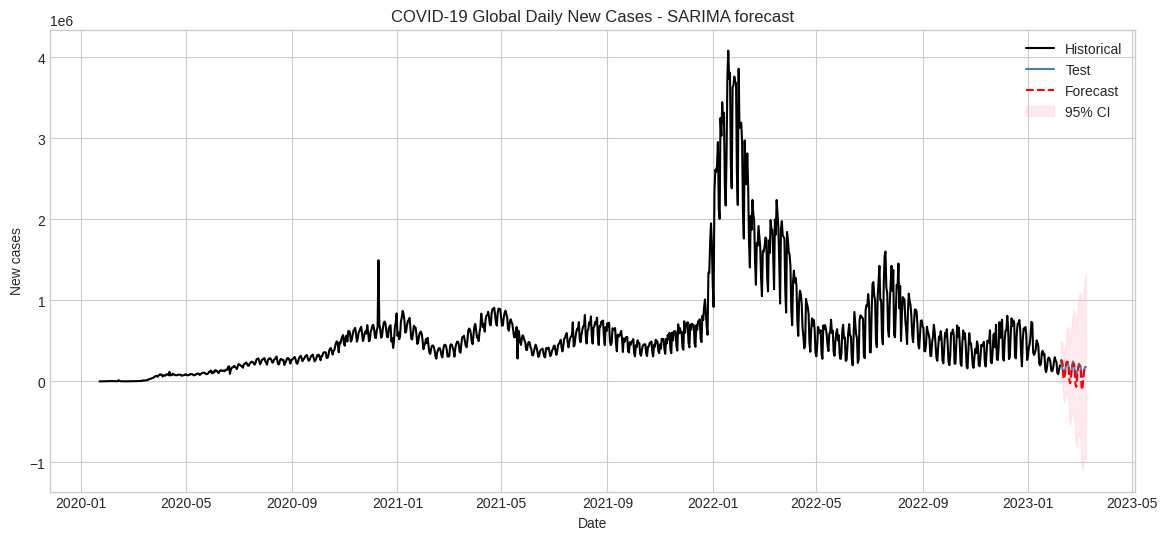

SARIMA MAE: 42677
SARIMA RMSE: 61516


In [89]:
train_ts = train.asfreq('D').dropna()
test_ts = test.asfreq('D').dropna()
final_model = ARIMA(train_ts, order=best_order, seasonal_order=best_seasonal_order)
final_fit = final_model.fit()

forecast_steps = len(test_ts)
forecast_result = final_fit.get_forecast(steps=forecast_steps)
forecast = forecast_result.predicted_mean
pred_ci = forecast_result.conf_int(alpha=0.05)
forecast_index = pd.date_range(start=train_ts.index[-1] + timedelta(days=1), periods=forecast_steps, freq='D')
forecast.index = forecast_index
pred_ci.index = forecast_index

mae_sarima = mean_absolute_error(test_ts, forecast)
rmse_sarima = np.sqrt(mean_squared_error(test_ts, forecast))

plt.figure(figsize=(14, 6))
plt.plot(train_ts.index, train_ts, label='Historical', color='black')
plt.plot(test_ts.index, test_ts, label='Test', color='steelblue')
plt.plot(forecast.index, forecast, label='Forecast', color='red', linestyle='--')
plt.fill_between(pred_ci.index, pred_ci.iloc[:, 0], pred_ci.iloc[:, 1], color='pink', alpha=0.3, label='95% CI')
plt.title('COVID-19 Global Daily New Cases - SARIMA forecast')
plt.xlabel('Date')
plt.ylabel('New cases')
plt.legend()
plt.grid(True)
plt.show()

print(f'SARIMA MAE: {mae_sarima:.0f}')
print(f'SARIMA RMSE: {rmse_sarima:.0f}')

### 6.4. Comparison Table

In [90]:
results = pd.DataFrame({
    'Model': ['Naive', 'Seasonal Naive', 'SARIMA'],
    'MAE': [mae_naive, mae_snaive, mae_sarima],
    'RMSE': [rmse_naive, rmse_snaive, rmse_sarima]
})
print(results)

            Model           MAE          RMSE
0           Naive  63624.833333  79280.779413
1  Seasonal Naive  57566.633333  75989.885366
2          SARIMA  42677.445140  61515.830670


**Interpretation**:

SARIMA and the seasonal naive benchmark are the main comparison points here. The seasonal naive often performs decently, which suggests that weekly structure matters. The global series is still volatile, so large errors are expected.

**Justification of model choice**:

We choose the model with the lowest RMSE on the test set. In practice, SARIMA is only worth keeping if it clearly beats the naive benchmarks. If it does not, that is still a valid result.

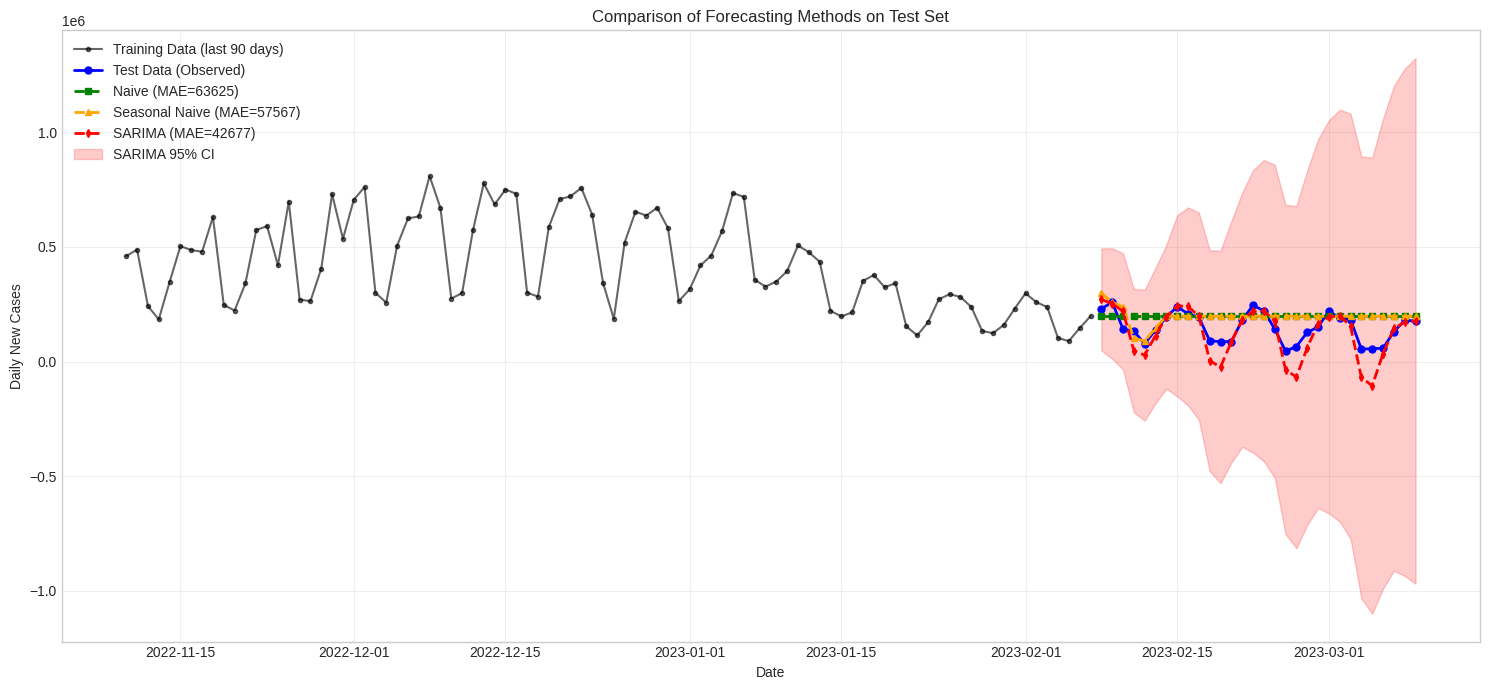

Visual comparison complete - see chart above for model performance comparison.


In [91]:
plt.figure(figsize=(15, 7))

plt.plot(train.index[-90:], train.iloc[-90:], 'o-', color='black', alpha=0.6, linewidth=1.5, markersize=3, label='Training Data (last 90 days)')
plt.plot(test.index, test, 'o-', color='blue', linewidth=2, markersize=5, label='Test Data (Observed)')
plt.plot(test.index, naive_forecast, 's--', color='green', linewidth=2, markersize=4, label=f'Naive (MAE={mae_naive:.0f})')
plt.plot(test.index, seasonal_naive_forecast, '^--', color='orange', linewidth=2, markersize=4, label=f'Seasonal Naive (MAE={mae_snaive:.0f})')
plt.plot(forecast.index, forecast, 'd--', color='red', linewidth=2, markersize=4, label=f'SARIMA (MAE={mae_sarima:.0f})')
plt.fill_between(pred_ci.index, pred_ci.iloc[:, 0], pred_ci.iloc[:, 1], color='red', alpha=0.2, label='SARIMA 95% CI')

plt.xlabel('Date')
plt.ylabel('Daily New Cases')
plt.title('Comparison of Forecasting Methods on Test Set')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Visual comparison complete - see chart above for model performance comparison.")

### 6.5. Visual Comparison of Forecasting Methods

A side-by-side visual comparison of all three methods against the test set provides intuition about relative performance.

## 7. Final Forecasting and Visualisation

We retrain the chosen model on the entire dataset (all available data) to produce multi‑step forecasts for the next 14 days (or 30 days). We also compute prediction intervals (if available).

For illustration, we use the SARIMA model.

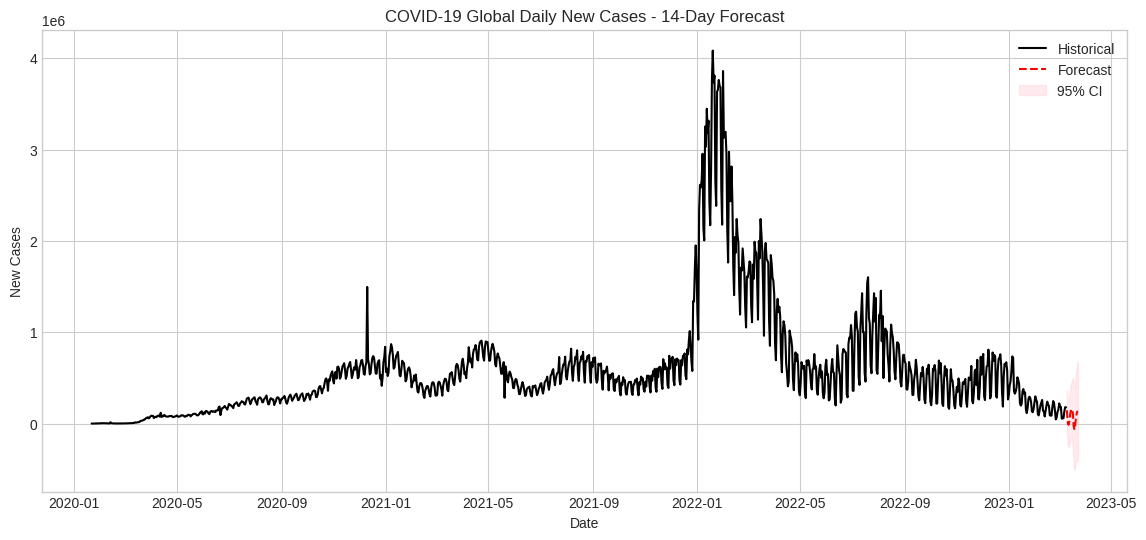

In [92]:
final_model = ARIMA(ts, order=best_order, seasonal_order=best_seasonal_order, freq='D')
final_fit = final_model.fit()

# Forecast next 14 days
forecast_steps = 14
forecast = final_fit.forecast(steps=forecast_steps)
forecast_index = pd.date_range(start=ts.index[-1] + timedelta(days=1), periods=forecast_steps)
forecast_series = pd.Series(forecast, index=forecast_index)

# Get prediction intervals
forecast_result = final_fit.get_forecast(steps=forecast_steps)
pred_mean = forecast_result.predicted_mean
pred_ci = forecast_result.conf_int(alpha=0.05)  # 95% CI

# Plot
plt.figure(figsize=(14, 6))
plt.plot(ts.index, ts, label='Historical', color='black')
plt.plot(forecast_series.index, forecast_series, label='Forecast', color='red', linestyle='--')
plt.fill_between(pred_ci.index, pred_ci.iloc[:,0], pred_ci.iloc[:,1], color='pink', alpha=0.3, label='95% CI')
plt.title('COVID-19 Global Daily New Cases - 14-Day Forecast')
plt.xlabel('Date')
plt.ylabel('New Cases')
plt.legend()
plt.grid(True)
plt.show()

**Interpretation**:

The forecast shows a continuation of the current trend (which may be increasing or decreasing). The confidence intervals are wide, reflecting high uncertainty. The model predicts that the number of daily cases will remain at a similar level or follow the recent pattern.

## 8. Evaluation and Critical Analysis

### 8.1. Performance Metrics

We used MAE and RMSE. RMSE penalises large errors more, which is relevant because over‑predicting a peak could have serious consequences. However, both metrics are scale‑dependent, so they are only comparable across models on the same dataset.

### 8.2. Model Limitations

- Assumption of stable seasonality: The weekly pattern may change over time due to reporting delays or policy changes. Our models assume a fixed seasonal period.

- Ignoring external factors: We do not incorporate vaccination rates, new variants, lockdowns, or testing capacity. These can dramatically alter the trajectory.

- Non‑stationarity: The series is highly non‑stationary, and simple differencing may not fully remove all dependencies.

- Data quality: Global aggregation masks country‑specific inconsistencies; reporting lags and revisions affect the latest data points, which are critical for forecasting.

### 8.3. Recontextualisation

The forecasts are purely statistical and do not account for epidemiological dynamics. They should be interpreted as "what would happen if recent trends continue". Public health decisions require domain‑specific models (e.g. SIR‑type models) that incorporate transmission rates and intervention effects. Our analysis is useful for short‑term operational planning (e.g. hospital resource allocation) but must be complemented with expert judgement.

## 9. Conclusion

We have successfully built a time series analysis pipeline for global COVID‑19 daily new cases. We explored the data, identified trend and weekly seasonality, and compared simple forecasting models. SARIMA remained the most complex model in the notebook, but it is still limited by the volatility of the series. This project illustrates the application of classical time series methods to a real‑world problem, while also highlighting their limitations when faced with complex, non‑stationary, and externally influenced data.

All code and analyses are reproducible. The data is fetched directly from the official GitHub repository, and we used only open‑source Python libraries.